In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mpc
import seaborn as sns
import numpy as np
dcolors = plt.cm.tab10.colors
from pathlib import Path
import statsmodels.formula.api as sm
from scipy.stats import linregress
import scipy.stats as st
sns.set_theme(font_scale = 1, style = 'ticks')

from scikit_posthocs import posthoc_dunn, posthoc_conover
from statannotations.Annotator import Annotator
import itertools 



In [70]:
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['font.monospace'] = 'Courier New'

In [71]:
git_folder = Path('../../..')
figure_folder = git_folder / 'Figures'

In [72]:
fn = git_folder / 'data' / 'other'/'A_rates_and_values.csv'
df_rates = pd.read_csv(fn, index_col=0)


In [73]:
fn_classification = git_folder / 'data'/'this_project'/'5_div'/'5D_classyfire_classification.csv'
df_classyfire = pd.read_csv(fn_classification, index_col=0)
met_to_class = df_classyfire.set_index('Metabolite')['Defined class'].to_dict()

In [74]:
df_rates['Compound class'] = df_rates.Metabolite.map(met_to_class)

In [75]:
df_rates.rename(columns = {'xlogP': 'log P'}, inplace=True)
df_rates['log10(Intracellular conc. [M])'] = np.log10(df_rates['Intracellular concentration [M]'])


In [76]:
df_rates.replace({'Species': {'Ecoli': 'E. coli', 'Pputida': 'P. putida'}}, inplace=True)

In [77]:
df_rates.loc[(df_rates['Carbon source'] == 'Galactose')&
             (df_rates.Metabolite.isin(['Lactate', 'Pyruvate', 'Citrate', 'Isocitrate', 'Cis-aconitate'])), ['Metabolite', 'Metabolite value [gDW/mmol]']]

,Metabolite,Metabolite value [gDW/mmol]
57,Cis-aconitate,0.063960
60,Citrate,0.063864
147,Isocitrate,0.064213
153,Lactate,0.037631
225,Pyruvate,0.031561


# Simple linear model of E. coli in controlled conditions


In [78]:
df_mean = df_rates.groupby(['Carbon source', 'Species', 'Metabolite', 'Dataset']).mean(numeric_only=True)
df_mean.reset_index(inplace=True)
df_mean['Compound class'] = df_mean.Metabolite.map(met_to_class)

df_mean.replace([np.inf, -np.inf], np.nan, inplace=True)

df_mean_ecoli = df_mean.loc[(df_mean.Species=='E. coli')&(df_mean.Dataset != 'Vila-23')].copy()


In [79]:
df_mean_ecoli.dropna(subset=['Rate [mmol/gDW/h]', 'Metabolite value [gDW/mmol]'], inplace=True)


In [80]:
df_mean_ecoli['Compound class'].unique()

array(['Carboxylic acids', 'Amino acids', 'Organooxygen compounds',
       'Keto / hydroxy acids', 'Other'], dtype=object)

In [81]:
key_to_col = {
    'Y':'log10(Rate [mmol/gDW/h])',
    'A':'log10(Intracellular conc. [M])',
    'B':'log10(Metabolite value [gDW/mmol])',
    'C':'Charge',
    'D':'Mol weight [g/mol]',
    'E':'log P',
    'F':'log10(Turnover [mmol/gDW/h])',
    'R':'Rotatable Bond Count',
    'S':'Hydrogen Bond Donor Count',
    'T':'Hydrogen Bond Acceptor Count',
    'U':'Topological Polar Surface Area',
    'G':'Compound class',
    'H':'Carbon source',
    # 'V':'Simplified class',
}
lindf = pd.DataFrame()
lindf['Y'] = df_mean_ecoli['log10(Rate [mmol/gDW/h])']
lindf['A'] = df_mean_ecoli['log10(Intracellular conc. [M])']
lindf['B'] = df_mean_ecoli['log10(Metabolite value [gDW/mmol])']
lindf['C'] = df_mean_ecoli['Charge']
lindf['D'] = df_mean_ecoli['Mol weight [g/mol]']
lindf['E'] = df_mean_ecoli['log P']
lindf['F'] = df_mean_ecoli['log10(Turnover [mmol/gDW/h])'].copy()
lindf['R'] = df_mean_ecoli['Rotatable Bond Count']
lindf['S'] = df_mean_ecoli['Hydrogen Bond Donor Count']
lindf['T'] = df_mean_ecoli['Hydrogen Bond Acceptor Count']
lindf['U'] = df_mean_ecoli['Topological Polar Surface Area']
lindf['G'] = df_mean_ecoli['Compound class']
lindf['H'] = df_mean_ecoli['Carbon source']
lindf['H'] = pd.Categorical(lindf['H'], categories=lindf.H.unique())
lindf['G'] = pd.Categorical(lindf['G'], categories=lindf.G.unique())
lindf['Metabolite'] = df_mean_ecoli['Metabolite']
lindf.fillna({'F':-4}, inplace = True)
lindf.dropna(inplace=True)

var_explained = {}
for key, col_name in key_to_col.items():
    if col_name == 'log10(Rate [mmol/gDW/h])':
        continue
    if key not in lindf.columns:
        continue
    res = sm.ols(formula=f"Y ~ {key}", data=lindf, missing='drop').fit(
        cov_type="cluster", cov_kwds={"groups": lindf["Metabolite"]})
    var_explained[col_name] = res.rsquared
    print(key, col_name, f'R2: {res.rsquared:.2f}', f'p-value: {res.pvalues[1]:.2e}')

ols_model =  sm.ols(formula="Y ~ A+B+C+G", data=lindf, missing='drop')
res = ols_model.fit()
var_explained['log10(MV) + log10(IC) + Charge + C class'] = res.rsquared
print(var_explained)
df_r2 = pd.DataFrame(var_explained, index = ['Variability explained']).T.reset_index(names = 'Parameter').sort_values(by= 'Variability explained', ascending = False)
# Export the OLS summary to a CSV file
summary_df = res.summary2().tables[1]  # Extract the coefficients table as a DataFrame
summary_df.to_csv(figure_folder / 'ols_summary.csv')


A log10(Intracellular conc. [M]) R2: 0.08 p-value: 3.11e-02
B log10(Metabolite value [gDW/mmol]) R2: 0.43 p-value: 5.22e-11
C Charge R2: 0.04 p-value: 7.54e-02
D Mol weight [g/mol] R2: 0.11 p-value: 3.14e-02
E log P R2: 0.19 p-value: 1.48e-02
F log10(Turnover [mmol/gDW/h]) R2: 0.04 p-value: 4.90e-02
R Rotatable Bond Count R2: 0.19 p-value: 1.32e-02
S Hydrogen Bond Donor Count R2: 0.18 p-value: 2.30e-02
T Hydrogen Bond Acceptor Count R2: 0.05 p-value: 1.32e-01
U Topological Polar Surface Area R2: 0.05 p-value: 1.38e-01
G Compound class R2: 0.29 p-value: 1.95e-02
H Carbon source R2: 0.04 p-value: 1.90e-01
{'log10(Intracellular conc. [M])': np.float64(0.07653525742533884), 'log10(Metabolite value [gDW/mmol])': np.float64(0.42987846111170025), 'Charge': np.float64(0.03593401599726731), 'Mol weight [g/mol]': np.float64(0.11347823733697782), 'log P': np.float64(0.18731011613421622), 'log10(Turnover [mmol/gDW/h])': np.float64(0.042076548190855934), 'Rotatable Bond Count': np.float64(0.1940986

/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/2125844534.py:46: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(key, col_name, f'R2: {res.rsquared:.2f}', f'p-value: {res.pvalues[1]:.2e}')
/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/2125844534.py:46: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(key, col_name, f'R2: {res.rsquared:.2f}', f'p-value: {res.pvalues[1]:.2e}')
/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/2125844534.py:46: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will alwa

In [82]:
ols_model =  sm.ols(formula="Y ~ B+C+G", data=lindf)
res = ols_model.fit()
res.summary2()
summary_df = res.summary2().tables[1]  # Extract the coefficients table as a DataFrame
summary_df.to_csv(figure_folder / 'ols_summary_value_group_charge.csv')

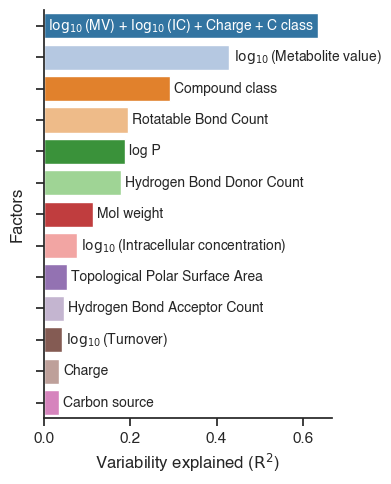

In [83]:

fig, ax = plt.subplots(1, figsize = (4,5))
# Replace 'log10' in the 'Parameter' column with LaTeX-style formatting
df_r2['Parameter name'] = df_r2['Parameter'].str.replace('log10', r'$\log_{10}$', regex=False)
df_r2.replace({'Parameter name': {r'$\log_{10}$(Metabolite value [gDW/mmol])': r'$\log_{10}$(Metabolite value)',
                                  'Mol weight [g/mol]': 'Mol weight',
                                  r'$\log_{10}$(Intracellular conc. [M])': r'$\log_{10}$(Intracellular concentration)',
                                   r'$\log_{10}$(Turnover [mmol/gDW/h])':  r'$\log_{10}$(Turnover)',}}, inplace=True),

g = sns.barplot(data = df_r2, x = 'Variability explained', y = 'Parameter name', palette='tab20', hue = 'Parameter name', ax = ax)
ax.set_yticklabels([])

# Add custom labels at the end of the bars
for i, (value, label) in enumerate(zip(df_r2['Variability explained'], df_r2['Parameter name'])):
    if i < 1:
        ax.text(0.01, i, label, #label.replace('$\log_{10}$', '$\mathbf{log_{10}}$'),
                va='center', ha='left', fontsize=10, color='w')#, weight = 'bold')
    else:
        ax.text(value + 0.01, i, label, va='center', ha='left', fontsize=10)  # Adjust `+ 0.01` for spacing

sns.despine()
ax.set_xlabel(r"Variability explained ($\rm{R^2}$)", )
ax.set_ylabel("Factors")
# ax.set_ylim(0,0.5)
plt.tight_layout()
plt.savefig(figure_folder / "Variability_explained_ecoli_std.pdf")

# Estimate variance between conditions

In [84]:
# Pivot to metabolites x carbon sources using metabolite value
# If there are repeated metabolite/carbon-source rows, average them.
df_mean_ecoli_pivot = df_mean_ecoli.pivot_table(
    index='Metabolite',
    columns='Carbon source',
    values='log10(Rate [mmol/gDW/h])',
    # aggfunc='mean'
)
df_mean_ecoli_pivot = df_mean_ecoli_pivot.loc[df_mean_ecoli_pivot.isna().sum(axis=1) < 3].copy()  # Keep only metabolites with at least 2 non-NA values
print(f"Shape: {df_mean_ecoli_pivot.shape}")
print(f"Carbon source columns: {list(df_mean_ecoli_pivot.columns)}")
display(df_mean_ecoli_pivot)

between_var = df_mean_ecoli_pivot.mean(axis=1).var()
within_var = df_mean_ecoli_pivot.var(axis=1).mean()
print(f"Between-metabolite variance: {between_var:.4f}")
print(f"Within-metabolite variance: {within_var:.4f}")
noise_fraction = within_var / (between_var + within_var)
print(f"Estimated noise fraction: {noise_fraction:.2f}")

Shape: (25, 4)
Carbon source columns: ['Galactose', 'Glucose', 'L-alanine', 'L-malate']


Carbon source,Galactose,Glucose,L-alanine,L-malate
Metabolite,,,,
Acetate,-0.690957,0.188859,0.325205,-0.211787
Asparagine,NaN,NaN,-2.234990,-3.554506
Aspartate,-3.918115,-4.275236,-4.527042,NaN
Beta-alanine,-4.548518,NaN,-3.309645,-3.929882
Cis-aconitate,-3.989877,-3.199390,-3.039151,-3.357620
Formate,-0.447022,NaN,-1.131041,-1.112279
Gamma-aminobutyrate,-5.037953,NaN,-2.564025,-3.847028
Glutamate,-2.748128,NaN,-3.203837,-2.910969
Glycine,NaN,-4.887602,-1.719007,NaN


Between-metabolite variance: 2.0708
Within-metabolite variance: 0.5378
Estimated noise fraction: 0.21


# Try all different linear models

In [85]:
n = 0
adjusted_r2_data = []
letters = 'ABCDEFGHRSTU'
for x in range(1, len(letters)+1, 1):
    for x in itertools.combinations(letters, x):
        rhs = " + ".join(x)
        ols_model =  sm.ols(formula=f"Y ~ {rhs}", data=lindf)
        res = ols_model.fit(cov_type="cluster", cov_kwds={"groups": lindf["Metabolite"]})
        adjusted_r2_data.append([x, len(x), res.rsquared_adj, res.rsquared, res.aic, res.bic, res.df_model])
        n+=1
        
adjusted_r2_df = pd.DataFrame(adjusted_r2_data, columns = ['Combination', 'N', 'rsquared_adj', 'rsquared', 'aic', 'bic', 'df'])

In [86]:
adjusted_r2_df.sort_values(by = 'rsquared_adj', ascending=False, inplace=True)
adjusted_r2_df.reset_index(inplace=True, drop=True)

In [87]:
adjusted_r2_df['Contains B'] = adjusted_r2_df.Combination.apply(lambda x: 'B' in x)
adjusted_r2_df['Contains BG'] = adjusted_r2_df.Combination.apply(lambda x: 'B' in x and 'G' in x)
adjusted_r2_df['Contains B or G'] = adjusted_r2_df.Combination.apply(lambda x: 'B' in x or 'G' in x)
adjusted_r2_df['Contains ABG'] = adjusted_r2_df.Combination.apply(lambda x: set('ABG') <= set(str(x)))

In [88]:
adjusted_r2_df.sort_values('bic').head(10)

,Combination,N,rsquared_adj,rsquared,aic,bic,df,Contains B,Contains BG,Contains B or G,Contains ABG
510,"(A, B, C, G)",4,0.604046,0.634504,238.185591,258.359900,7.0,True,True,True,True
362,"(A, B, C, D, G)",5,0.616864,0.650546,236.056360,258.752457,8.0,True,True,True,True
388,"(A, C, D, E, G)",5,0.614295,0.648203,236.671140,259.367237,8.0,False,False,True,False
412,"(A, B, C, G, T)",5,0.611676,0.645814,237.293819,259.989916,8.0,True,True,True,True
248,"(A, B, C, D, E, G)",6,0.625104,0.662182,234.940852,260.158738,9.0,True,True,True,True
249,"(A, C, D, E, G, S)",6,0.625045,0.662128,234.955532,260.173418,9.0,False,False,True,False
436,"(A, B, C, G, R)",5,0.609833,0.644134,237.729259,260.425356,8.0,True,True,True,True
277,"(A, B, C, E, G, T)",6,0.623448,0.660689,235.346582,260.564468,9.0,True,True,True,True
278,"(A, B, C, D, G, U)",6,0.623437,0.660679,235.349237,260.567123,9.0,True,True,True,True
457,"(A, E, G, S, T)",5,0.608449,0.642871,238.055099,260.751197,8.0,False,False,True,False


In [89]:
adjusted_r2_df.loc[~adjusted_r2_df['Contains B']].sort_values('bic').head(10)

,Combination,N,rsquared_adj,rsquared,aic,bic,df,Contains B,Contains BG,Contains B or G,Contains ABG
388,"(A, C, D, E, G)",5,0.614295,0.648203,236.671140,259.367237,8.0,False,False,True,False
249,"(A, C, D, E, G, S)",6,0.625045,0.662128,234.955532,260.173418,9.0,False,False,True,False
457,"(A, E, G, S, T)",5,0.608449,0.642871,238.055099,260.751197,8.0,False,False,True,False
332,"(A, E, G, S, T, U)",6,0.619662,0.657277,236.266948,261.484834,9.0,False,False,True,False
338,"(A, C, E, G, S, T)",6,0.619191,0.656853,236.380757,261.598642,9.0,False,False,True,False
3,"(A, C, D, E, G, H, S)",7,0.658887,0.703869,228.824023,261.607274,12.0,False,False,True,False
70,"(A, C, D, E, G, H)",6,0.645729,0.688553,231.463253,261.724716,11.0,False,False,True,False
365,"(A, E, F, G, S, T)",6,0.616424,0.654360,237.046780,262.264666,9.0,False,False,True,False
540,"(A, C, E, G, T)",5,0.601136,0.636201,239.757605,262.453703,8.0,False,False,True,False
722,"(A, C, D, G)",4,0.584733,0.616677,242.567032,262.741341,7.0,False,False,True,False


In [90]:
adjusted_r2_df.loc[~adjusted_r2_df['Contains B or G']].sort_values('rsquared_adj', ascending=False).head(10)

,Combination,N,rsquared_adj,rsquared,aic,bic,df,Contains B,Contains BG,Contains B or G,Contains ABG
2929,"(A, D, E, H, R, S, U)",7,0.433324,0.489369,272.949766,298.167652,9.0,False,False,False,False
2934,"(A, C, D, H, R, S, U)",7,0.432005,0.488180,273.163736,298.381622,9.0,False,False,False,False
2938,"(A, D, E, H, R, U)",6,0.431413,0.481399,272.374584,295.070681,8.0,False,False,False,False
2942,"(A, D, E, H, R, S, T, U)",8,0.430804,0.493353,274.229161,301.968835,10.0,False,False,False,False
2950,"(A, C, D, E, H, R, S, U)",8,0.429458,0.492155,274.446467,302.186142,10.0,False,False,False,False
2966,"(A, D, E, F, H, R, S, U)",8,0.426631,0.489638,274.901221,302.640895,10.0,False,False,False,False
2968,"(A, C, D, F, H, R, S, U)",8,0.426529,0.489548,274.917566,302.657241,10.0,False,False,False,False
2970,"(A, D, E, H, R, T, U)",7,0.425920,0.482697,274.144017,299.361903,9.0,False,False,False,False
2978,"(A, C, D, H, R, S, T, U)",8,0.425039,0.488222,275.156205,302.895879,10.0,False,False,False,False
2979,"(A, D, E, F, H, R, U)",7,0.424796,0.481684,274.323953,299.541839,9.0,False,False,False,False


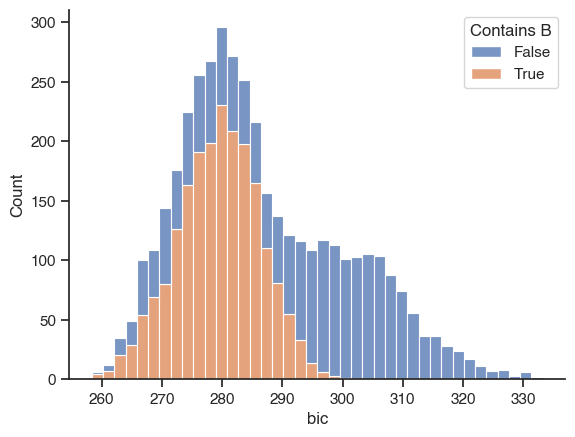

In [91]:

ax = sns.histplot(data = adjusted_r2_df, x = 'bic', bins = 40, hue = 'Contains B', multiple="stack")
sns.despine()

In [92]:
adjusted_r2_df.sort_values(by='bic', ascending=True, inplace=True)
selected = adjusted_r2_df.iloc[0]
selected_no_B = adjusted_r2_df.loc[~adjusted_r2_df['Contains B']].iloc[0]

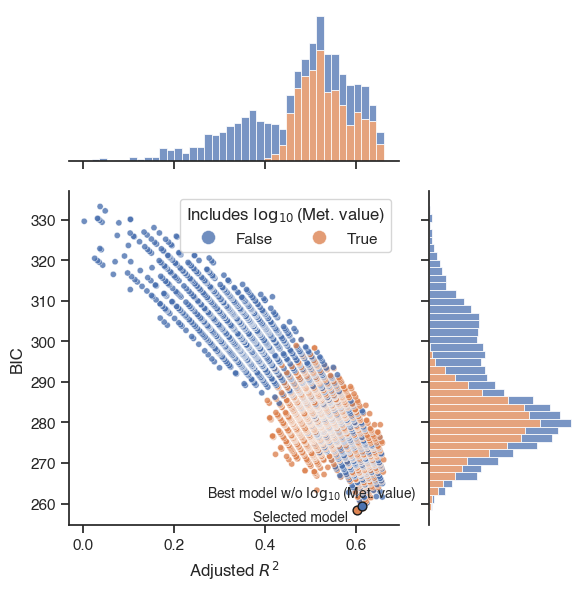

In [93]:
g = sns.JointGrid(data=adjusted_r2_df, x='rsquared_adj', y='bic', hue='Contains B', palette=['C0', 'C1'], ratio = 2)

# Scatter plot on joint axis
sns.scatterplot(data = adjusted_r2_df, x = 'rsquared_adj', y = 'bic', hue = 'Contains B', alpha=0.8, s=20,
                  ax = g.ax_joint,)


sns.histplot(data = adjusted_r2_df, y = 'bic', bins = 40, hue = 'Contains B', multiple="stack", ax = g.ax_marg_y, legend=False)
sns.histplot(data = adjusted_r2_df, x = 'rsquared_adj', bins = 40, hue = 'Contains B', multiple="stack", ax = g.ax_marg_x, legend=False)

leg = g.ax_joint.legend(ncol=2)
leg.set_title(r"Includes $\log_{10}$(Met. value)")
for handle in leg.legend_handles:
    handle.set_markersize(10)
g.ax_joint.set_xlabel(r"Adjusted $R^2$")
g.ax_joint.set_ylabel("BIC")

g.ax_joint.scatter(x = selected.rsquared_adj, y = selected.bic, color='C1', s=40, label='Selected model', edgecolors='k')
g.ax_joint.annotate('Selected model', xy=(selected.rsquared_adj, selected.bic), xytext=(selected.rsquared_adj - 0.02, selected.bic),
                    ha='right', va='top', size = 10)

g.ax_joint.scatter(x = selected_no_B.rsquared_adj, y = selected_no_B.bic, color='C0', s=40, label='Selected model', edgecolors='k')
g.ax_joint.annotate(r"Best model w/o $\log_{10}$(Met. value)", xy=(selected.rsquared_adj, selected.bic), xytext=(selected.rsquared_adj-0.1, selected.bic+2),
                    ha='center', va='bottom', size=10)

plt.savefig(figure_folder / "Adjusted_R2_vs_BIC.pdf", bbox_inches='tight')
plt.savefig(figure_folder / "Adjusted_R2_vs_BIC.png", bbox_inches='tight', dpi=300)

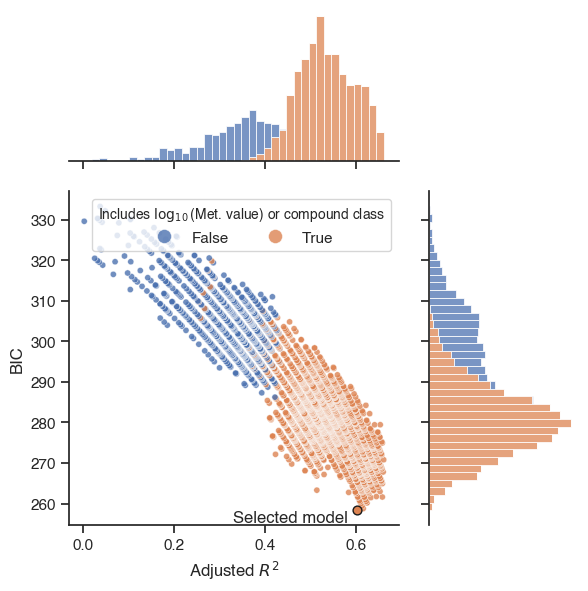

In [94]:
g = sns.JointGrid(data=adjusted_r2_df, x='rsquared_adj', y='bic', hue='Contains B or G', palette=['C0', 'C1'], ratio = 2)

# Scatter plot on joint axis
sns.scatterplot(data = adjusted_r2_df, x = 'rsquared_adj', y = 'bic', hue = 'Contains B or G', alpha=0.8, s=20,
                  ax = g.ax_joint,)


sns.histplot(data = adjusted_r2_df, y = 'bic', bins = 40, hue = 'Contains B or G', multiple="stack", ax = g.ax_marg_y, legend=False)
sns.histplot(data = adjusted_r2_df, x = 'rsquared_adj', bins = 40, hue = 'Contains B or G', multiple="stack", ax = g.ax_marg_x, legend=False)

leg = g.ax_joint.legend(ncol=2)
leg.set_title(r"Includes $\log_{10}$(Met. value) or compound class", prop={'size': 10})
for handle in leg.legend_handles:
    handle.set_markersize(10)
g.ax_joint.set_xlabel(r"Adjusted $R^2$")
g.ax_joint.set_ylabel("BIC")

# selected = adjusted_r2_df.iloc[510]
g.ax_joint.scatter(x = selected.rsquared_adj, y = selected.bic, color='C1', s=40, label='Selected model', edgecolors='k')
g.ax_joint.annotate('Selected model', xy=(selected.rsquared_adj, selected.bic), xytext=(selected.rsquared_adj - 0.02, selected.bic),
                    ha='right', va='top')


plt.savefig(figure_folder / "Adjusted_R2_vs_BIC_B_or_G.pdf", bbox_inches='tight')
plt.savefig(figure_folder / "Adjusted_R2_vs_BIC_B_or_G.png", bbox_inches='tight', dpi=300)

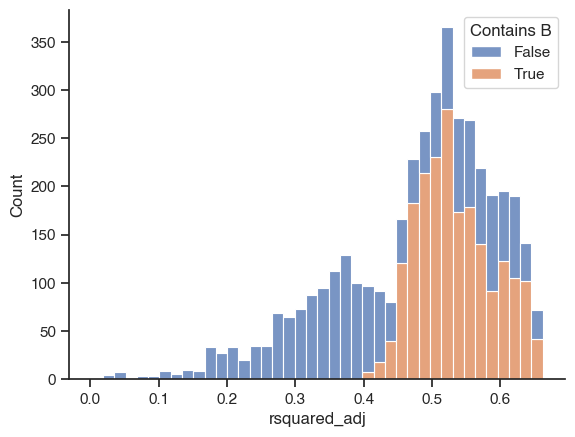

In [95]:
sns.histplot(data = adjusted_r2_df, x = 'rsquared_adj', bins = 40, hue = 'Contains B', multiple="stack")
sns.despine()

In [96]:
adjusted_r2_df.loc[~adjusted_r2_df['Contains B']].sort_values('bic', ascending=True).head(10)

,Combination,N,rsquared_adj,rsquared,aic,bic,df,Contains B,Contains BG,Contains B or G,Contains ABG
388,"(A, C, D, E, G)",5,0.614295,0.648203,236.671140,259.367237,8.0,False,False,True,False
249,"(A, C, D, E, G, S)",6,0.625045,0.662128,234.955532,260.173418,9.0,False,False,True,False
457,"(A, E, G, S, T)",5,0.608449,0.642871,238.055099,260.751197,8.0,False,False,True,False
332,"(A, E, G, S, T, U)",6,0.619662,0.657277,236.266948,261.484834,9.0,False,False,True,False
338,"(A, C, E, G, S, T)",6,0.619191,0.656853,236.380757,261.598642,9.0,False,False,True,False
3,"(A, C, D, E, G, H, S)",7,0.658887,0.703869,228.824023,261.607274,12.0,False,False,True,False
70,"(A, C, D, E, G, H)",6,0.645729,0.688553,231.463253,261.724716,11.0,False,False,True,False
365,"(A, E, F, G, S, T)",6,0.616424,0.654360,237.046780,262.264666,9.0,False,False,True,False
540,"(A, C, E, G, T)",5,0.601136,0.636201,239.757605,262.453703,8.0,False,False,True,False
722,"(A, C, D, G)",4,0.584733,0.616677,242.567032,262.741341,7.0,False,False,True,False


<Axes: xlabel='rsquared_adj', ylabel='Count'>

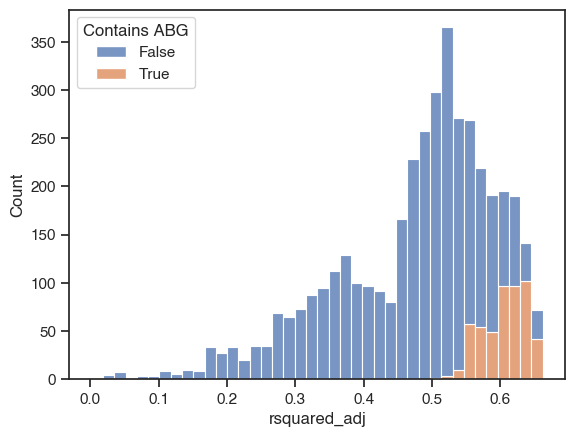

In [97]:
adjusted_r2_df['Contains ABG'] = adjusted_r2_df.Combination.apply(lambda x: set('ABG') <= set(str(x)))
sns.histplot(data = adjusted_r2_df, x = 'rsquared_adj', bins = 40, hue = 'Contains ABG', multiple="stack")

## Leave one out

In [142]:
lindf3 = lindf.sort_values('H').copy()
lindf3['G'] = pd.Categorical(lindf3['G'], categories=lindf3['G'].unique())
formula = "Y ~ A + B + G + C"
full_res = sm.ols(formula, data=lindf3).fit()

folds = []
for cs in lindf3['H'].unique():          # or cs_list, after checking names match
    test = lindf3['H'] == cs
    res = sm.ols(formula, data=lindf3.loc[~test]).fit()
    folds.append(pd.DataFrame({
        'Measured': lindf3.loc[test, 'Y'],
        'Predicted': res.predict(lindf3.loc[test]),
        'Carbon source': cs,
    }))
pred_df = pd.concat(folds)
assert pred_df['Predicted'].notna().all()

/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/2535706342.py:9: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res = sm.ols(formula, data=lindf3.loc[~test]).fit()


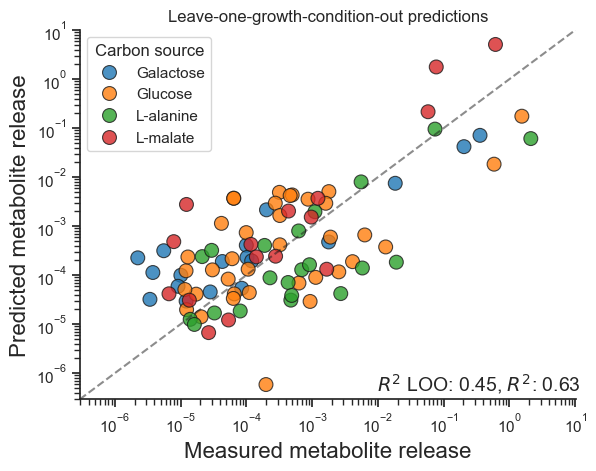

In [143]:
y, yhat = pred_df['Measured'], pred_df['Predicted']
R2 = 1 - ((yhat - y)**2).sum() / ((y - y.mean())**2).sum()

pred_df['Measured metabolite release'] = 10**y
pred_df['Predicted metabolite release'] = 10**yhat
ax = sns.scatterplot(data=pred_df, x='Measured metabolite release', y='Predicted metabolite release',
                     hue='Carbon source', s=100, edgecolor='k', palette='tab10', alpha=0.8)
ax.set(xscale='log', yscale='log')

lo = pred_df[['Measured metabolite release', 'Predicted metabolite release']].min().min() / 2
hi = pred_df[['Measured metabolite release', 'Predicted metabolite release']].max().max() * 2
ax.plot([lo, hi], [lo, hi], c='k', ls='--', alpha=0.5)
ax.set(xlim=(lo, hi), ylim=(lo, hi))   # square axes, so the diagonal is honest
sns.despine()
plt.xlabel('Measured metabolite release', fontdict={'size': 16})
plt.ylabel('Predicted metabolite release', fontdict={'size': 16})
plt.title('Leave-one-growth-condition-out predictions')
plt.text(0.6,0.02, "$R^2$ LOO: {0:.2f}, $R^2$: {1:.2f}".format(R2, full_res.rsquared), fontdict={'size': 14}, transform=ax.transAxes)
plt.savefig(figure_folder / 'LOO_ecoli_condition.pdf', bbox_inches='tight')
plt.savefig(figure_folder / 'LOO_ecoli_condition.png', bbox_inches='tight', dpi = 300)
plt.show()

# Leave one metabolite out

In [144]:
full_model =  sm.ols(formula="Y ~ A + B + G + C", data=lindf3)
full_res = full_model.fit()
y_preds2m = []
y_vals2m = []
met_labels = []
class_labels = []
for met in lindf3.Metabolite.unique():
    cidx = lindf3.Metabolite == met # "Carbon source" is represented by H in this df
    train_model = sm.ols(formula="Y ~ A + B + G + C", data=lindf3.loc[~cidx])
    train_res = train_model.fit()
    yp = train_res.predict(lindf3.loc[cidx, ['A', 'B', 'G', 'C']])
    y_vals2m += list(lindf3.loc[cidx, 'Y'].values)
    y_preds2m += list(yp)
    met_labels.extend(lindf3.loc[cidx, 'Metabolite'])
    class_labels.extend(lindf3.loc[cidx, 'G'])
print(f'Condition number: {np.linalg.cond(full_model.exog)}')


Condition number: 49.3176514047154


0.5026328085276259


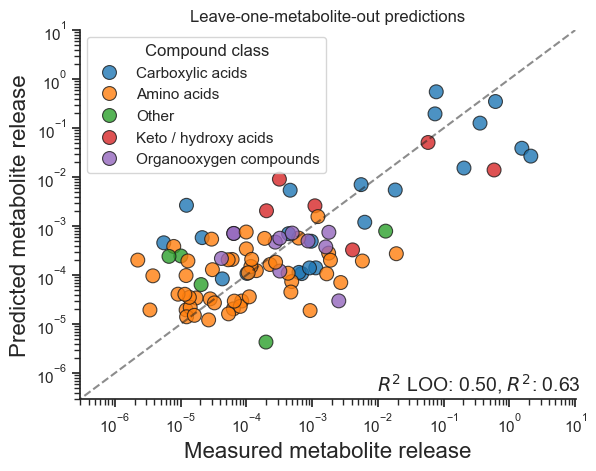

In [145]:

pred_df = pd.DataFrame()
pred_df['Predicted'] = y_preds2m
pred_df['Measured'] = y_vals2m
pred_df['Measured metabolite release'] = 10**pred_df['Measured']
pred_df['Predicted metabolite release'] = 10**pred_df['Predicted']
pred_df['Metabolite'] = met_labels
pred_df['Compound class'] = class_labels
ax = sns.scatterplot(data = pred_df, x = 'Measured metabolite release', y = 'Predicted metabolite release', hue = 'Compound class', s = 100,
                     edgecolor='k', palette = 'tab10', alpha = 0.8)

ax.set(xscale="log", yscale="log")
sns.despine()
llog = np.logspace(-7, 1)
ax.plot(llog,llog,c='k',ls = '--', alpha = 0.5)

# plt.legend(ncol = 2, loc = (1.05, 0))
y_preds_arr2 = np.array(y_preds2m)
y_vals_arr2 = np.array(y_vals2m)

SSres = np.sum((y_preds_arr2-y_vals_arr2)**2)
SStot = np.sum((y_vals_arr2-np.mean(y_vals_arr2))**2)
R2 = 1-(SSres/SStot)
print(R2)
R2_LOO_metabolite = R2
# ax.set(xscale="log", yscale="log")
ax.set(xlim=(lo, hi), ylim=(lo, hi))   # square axes, so the diagonal is honest

plt.xlabel('Measured metabolite release', fontdict={'size': 16})
plt.ylabel('Predicted metabolite release', fontdict={'size': 16})
plt.title('Leave-one-metabolite-out predictions')
plt.text(0.6,0.02, "$R^2$ LOO: {0:.2f}, $R^2$: {1:.2f}".format(R2, full_res.rsquared), fontdict={'size': 14}, transform=ax.transAxes)
plt.savefig(figure_folder / "LOO_ecoli_metabolite.pdf", bbox_inches='tight')
plt.savefig(figure_folder / "LOO_ecoli_metabolite.png", bbox_inches='tight', dpi=300)

# Leave one out with best model not including metabolite value

In [102]:
cs_list = df_mean_ecoli['Carbon source'].unique()
# lindf3.sort_values(by='H', inplace=True)
lindf3['G'] = pd.Categorical(lindf3['G'], categories=lindf3.G.unique())
full_model =  sm.ols(formula="Y ~ A + C + D + E + G", data=lindf3)
full_res = full_model.fit()
y_preds2 = []
y_vals2 = []
cs_labels = []
for cs in cs_list:
    cidx = lindf3['H']== cs # "Carbon source" is represented by H in this df
    train_model = sm.ols(formula="Y ~ A + C + D + E + G", data=lindf3.loc[~cidx])
    train_res = train_model.fit()
    yp = train_res.predict(lindf3.loc[cidx, ['A', 'C', 'D', 'E', 'G']])
    # test_model = sm.ols(formula="Y ~ A + B + G + C", data=lindf3.loc[cidx])
    # yp = test_model.predict(params=train_res.params, exog = full_model.exog[cidx])
    y_vals2 += list(lindf3.loc[cidx, 'Y'].values)
    y_preds2 += list(yp)
    cs_labels.extend(lindf3.loc[cidx, 'H'])
    print(len(y_vals2))
    


18
55
76
92


/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/2970682614.py:12: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  train_res = train_model.fit()


0.3055048469181759


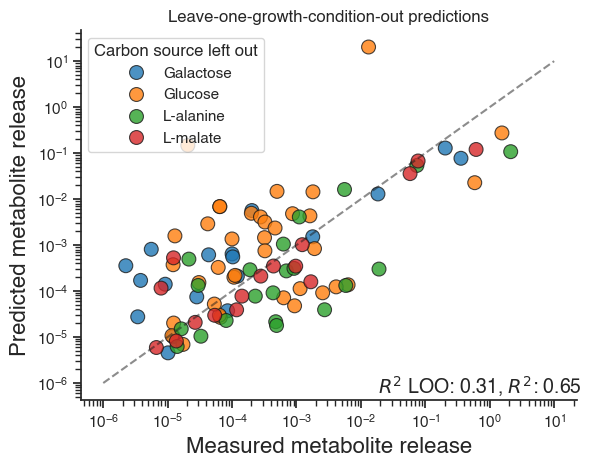

In [103]:
pred_df = pd.DataFrame()
pred_df['Predicted'] = y_preds2
pred_df['Measured'] = y_vals2
pred_df['Carbon source'] = cs_labels
# ax = sns.scatterplot(data = pred_df, x = 'Measured', y = 'Predicted', hue = 'Carbon source', s = 100)
pred_df['Measured metabolite release'] = 10**pred_df['Measured']
pred_df['Predicted metabolite release'] = 10**pred_df['Predicted']
ax = sns.scatterplot(data = pred_df, x = 'Measured metabolite release', y = 'Predicted metabolite release', hue = 'Carbon source', s = 100,
                     edgecolor='k', palette = 'tab10', alpha = 0.8)
ax.legend(title="Carbon source left out")
ax.set(xscale="log", yscale="log")
sns.despine()
llog = np.logspace(-6, 1)
ax.plot(llog,llog,c='k',ls = '--', alpha = 0.5)

y_preds_arr2 = np.array(y_preds2)
y_vals_arr2 = np.array(y_vals2)

SSres = np.sum((y_preds_arr2-y_vals_arr2)**2)
SStot = np.sum((y_vals_arr2-np.mean(y_vals_arr2))**2)
R2 = 1-(SSres/SStot)
print(R2)


plt.xlabel('Measured metabolite release', fontdict={'size': 16})
plt.ylabel('Predicted metabolite release', fontdict={'size': 16})
plt.title('Leave-one-growth-condition-out predictions')
plt.text(0.6,0.02, "$R^2$ LOO: {0:.2f}, $R^2$: {1:.2f}".format(R2, full_res.rsquared), fontdict={'size': 14}, transform=ax.transAxes)
plt.savefig(figure_folder / 'LOO_ecoli_condition_no_met_value.pdf', bbox_inches='tight')
plt.show()

In [104]:
mets = lindf3.Metabolite.unique()
full_model =  sm.ols(formula="Y ~ A + C + D + E + G", data=lindf3)
full_res = full_model.fit()
y_preds2m = []
y_vals2m = []
met_labels = []
class_labels = []
for met in mets:
    cidx = lindf3.Metabolite == met # "Carbon source" is represented by H in this df
    train_model = sm.ols(formula="Y ~ A + C + D + E + G", data=lindf3.loc[~cidx])
    train_res = train_model.fit()
    yp = train_res.predict(lindf3.loc[cidx, ['A', 'C', 'D', 'E', 'G']])
    # test_model = sm.ols(formula="Y ~ A + B + G + C", data=lindf3.loc[cidx])
    # yp = test_model.predict(params=train_res.params, exog = full_model.exog[cidx])
    y_vals2m += list(lindf3.loc[cidx, 'Y'].values)
    y_preds2m += list(yp)
    met_labels.extend(lindf3.loc[cidx, 'Metabolite'])
    class_labels.extend(lindf3.loc[cidx, 'G'])
    # print(len(y_vals2m))
    # y_pred = ols_model.predict(params = res.params, exog = lindf.loc[midx, xcolumns].T)
    # print(m, ols_model.exog.shape,res_full.rsquared_adj, res.rsquared_adj)
print(f'Condition number: {np.linalg.cond(full_model.exog)}')


Condition number: 1765.1324154274603


0.49574687963018516


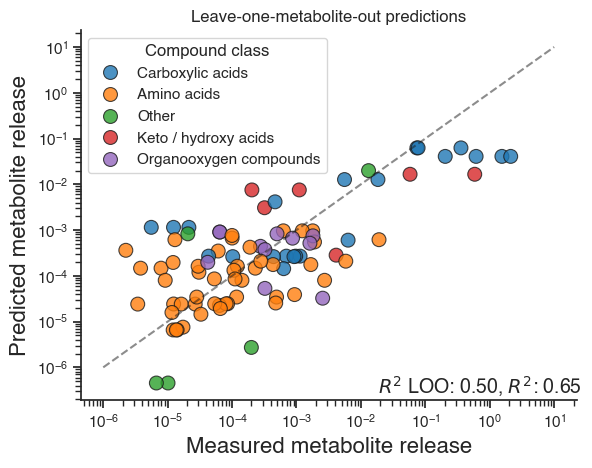

In [105]:

#     ax.scatter(y_vals[i], y_preds[i], label = mname,s = 70, alpha = 0.8, c = 'gray')#, color = cmap40(i))
pred_df = pd.DataFrame()
pred_df['Predicted'] = y_preds2m
pred_df['Measured'] = y_vals2m
pred_df['Measured metabolite release'] = 10**pred_df['Measured']
pred_df['Predicted metabolite release'] = 10**pred_df['Predicted']
pred_df['Metabolite'] = met_labels
pred_df['Compound class'] = class_labels
ax = sns.scatterplot(data = pred_df, x = 'Measured metabolite release', y = 'Predicted metabolite release', hue = 'Compound class', s = 100,
                     edgecolor='k', palette = 'tab10', alpha = 0.8)

ax.set(xscale="log", yscale="log")
sns.despine()
llog = np.logspace(-6, 1)
ax.plot(llog,llog,c='k',ls = '--', alpha = 0.5)

# plt.legend(ncol = 2, loc = (1.05, 0))
y_preds_arr2 = np.array(y_preds2m)
y_vals_arr2 = np.array(y_vals2m)

SSres = np.sum((y_preds_arr2-y_vals_arr2)**2)
SStot = np.sum((y_vals_arr2-np.mean(y_vals_arr2))**2)
R2 = 1-(SSres/SStot)
print(R2)
# ax.set(xscale="log", yscale="log")

plt.xlabel('Measured metabolite release', fontdict={'size': 16})
plt.ylabel('Predicted metabolite release', fontdict={'size': 16})
plt.title('Leave-one-metabolite-out predictions')
plt.text(0.6,0.02, "$R^2$ LOO: {0:.2f}, $R^2$: {1:.2f}".format(R2, full_res.rsquared), fontdict={'size': 14}, transform=ax.transAxes)
plt.savefig(figure_folder / "LOO_ecoli_metabolite_not_met_value.pdf", bbox_inches='tight')
plt.savefig(figure_folder / "LOO_ecoli_metabolite_not_met_value.png", bbox_inches='tight', dpi=300)

# Statistical comparison of LOO with or w/o metabolite value

In [106]:
top_n = 20
top_n_models = adjusted_r2_df.loc[adjusted_r2_df['Contains B']].head(top_n)['Combination'].apply(lambda x: ' + '.join(x))
top_n_models_no_B = adjusted_r2_df.loc[~adjusted_r2_df['Contains B']].head(top_n)['Combination'].apply(lambda x: ' + '.join(x))

In [107]:
# Create DataFrames with a column indicating the group
df_with_b = pd.DataFrame({
    'Model': top_n_models.values,
    'Type': 'With B'
})
df_without_b = pd.DataFrame({
    'Model': top_n_models_no_B.values,
    'Type': 'Without B'
})

# Concatenate into long-form
top_models_long = pd.concat([df_with_b, df_without_b], ignore_index=False)
top_models_long.reset_index(inplace=True)
print(top_models_long)

    index                      Model       Type
0       0              A + B + C + G     With B
1       1          A + B + C + D + G     With B
2       2          A + B + C + G + T     With B
3       3      A + B + C + D + E + G     With B
4       4          A + B + C + G + R     With B
5       5      A + B + C + E + G + T     With B
6       6      A + B + C + D + G + U     With B
7       7      A + B + C + G + T + U     With B
8       8          A + B + C + G + H     With B
9       9          A + B + C + G + U     With B
10     10          A + B + C + G + S     With B
11     11  A + B + E + G + S + T + U     With B
12     12  A + B + C + D + E + G + S     With B
13     13      A + B + C + D + G + T     With B
14     14          A + B + C + F + G     With B
15     15          A + B + C + E + G     With B
16     16  A + B + C + E + G + S + T     With B
17     17      A + B + C + D + F + G     With B
18     18      A + B + C + D + G + S     With B
19     19      A + B + C + D + G + H    

In [108]:
cs_list = df_mean_ecoli['Carbon source'].unique()
lindf3 = lindf.copy()
lindf3.sort_values(by='H', inplace=True)
lindf3['G'] = pd.Categorical(lindf3['G'], categories=lindf3.G.unique())
lindf3['H'] = pd.Categorical(lindf3['H'], categories=lindf3.H.unique())

lin_model_data = []
for _, row in top_models_long.iterrows():
    # print(row)
    model = row['Model']
    withB = row['Type']
    # full_model =  sm.ols(formula=f"Y ~ {model}", data=lindf3)
    # full_res = full_model.fit()
    full_res = np.nan
    y_preds2 = []
    y_vals2 = []
    for cs in cs_list:
        cidx = lindf3['H']== cs 
        train_model = sm.ols(formula=f"Y ~ {model}", data=lindf3.loc[~cidx])
        train_res = train_model.fit()
        factors = [x.strip() for x in model.split('+')]
        yp = train_res.predict(lindf3.loc[cidx, factors])
        y_vals2 += list(lindf3.loc[cidx, 'Y'].values)
        y_preds2 += list(yp)
    # plt.legend(ncol = 2, loc = (1.05, 0))
    y_preds_arr2 = np.array(y_preds2)
    y_vals_arr2 = np.array(y_vals2)

    SSres = np.sum((y_preds_arr2-y_vals_arr2)**2)
    SStot = np.sum((y_vals_arr2-np.mean(y_vals_arr2))**2)
    R2 = 1-(SSres/SStot)

    lin_model_data.append({
        'Model': model,
        'R2': R2,
        'With B': withB,
        'Rank': row['index'] + 1 }
    )
lin_model_df = pd.DataFrame(lin_model_data)
        


/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/2592720513.py:20: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  train_res = train_model.fit()
/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/2592720513.py:20: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  train_res = train_model.fit()
/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/2592720513.py:20: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  train_res = train_model.fit()
/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/2592720513.py:20: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  train_res = train_model.fit()
/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/2592720513.py:20: SingularMatrixWar

0.002557631011563264


/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/1709176501.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['With', 'Without'])


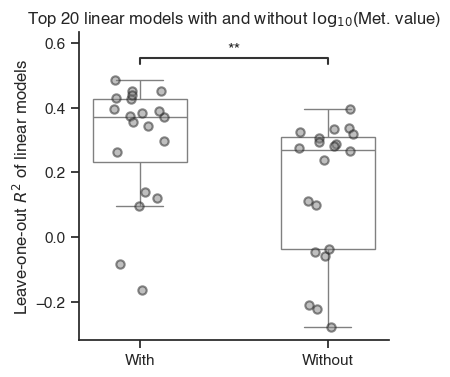

In [109]:
fig, ax = plt.subplots(figsize=(4, 4))

l = sns.boxplot(data=lin_model_df, y='R2', x='With B', width=0.5, fliersize=0, showfliers=False, 
            linewidth= 1, color = 'w', linecolor='grey')
sns.stripplot(data=lin_model_df, y='R2', x='With B', size=6, alpha=0.5, jitter=0.15, ax=l,
              edgecolor='k', linewidth=1.5, color = 'grey')


x1 = lin_model_df.loc[lin_model_df['With B'] == 'With B', 'R2']
x2 = lin_model_df.loc[lin_model_df['With B'] == 'Without B', 'R2']
stat, p_value = st.mannwhitneyu(x1, x2, alternative='greater')

# Add statannotations
pairs = [("With B", "Without B")]
annotator = Annotator(ax, pairs, data=lin_model_df, x="With B", y="R2")
annotator.configure(text_format='star', loc='inside', verbose=0)
annotator.set_pvalues_and_annotate(pvalues=[p_value])
print(p_value)
sns.despine()
ax.set_ylabel(r"Leave-one-out $R^2$ of linear models")
ax.set_xlabel("")
ax.set_title(r"Top 20 linear models with and without $\rm{log_{10}}$(Met. value)")
ax.set_xticklabels(['With', 'Without'])
plt.savefig(figure_folder / "LOO_linear_models_with_without_met_value.pdf", bbox_inches='tight')
plt.savefig(figure_folder / "LOO_linear_models_with_without_met_value.png", bbox_inches='tight', dpi=300)


In [110]:
print(x1.median(), x2.median(), x1.std(), x2.std(), x1.median()- x2.median())

0.3724759660042224 0.27063112540246864 0.18283106044816744 0.2154428328204228 0.10184484060175375


In [111]:

print(stat, p_value)

304.0 0.002557631011563264


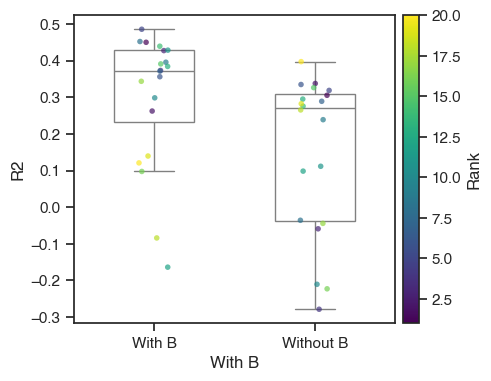

In [112]:
import matplotlib as mpl


fig, ax = plt.subplots(figsize=(5, 4))

l = sns.boxplot(data=lin_model_df, y='R2', x='With B', width=0.5, fliersize=0, showfliers=False, 
            linewidth= 1, color = 'w', linecolor='grey')
# sns.stripplot(data=lin_model_df, y='R2', x='With B', hue = 'Rank', palette='viridis', size=6, alpha=0.5, jitter=True, ax=l,
#               edgecolor='k', linewidth=0.5)

# Normalize the rank for the colormap
norm = mpl.colors.Normalize(vmin=lin_model_df['Rank'].min(), vmax=lin_model_df['Rank'].max())
scam = mpl.cm.ScalarMappable(cmap="viridis", norm=norm)
scam.set_array([])

# Plot stripplot with continuous color mapping
sns.stripplot(
    data=lin_model_df, y='R2', x='With B', hue='Rank', palette="viridis",
    size=4, alpha=0.7, jitter=True, ax=ax, dodge=False, legend=False
)

# Add colorbar
cbar = plt.colorbar(scam, ax=ax, pad=0.02)
cbar.set_label('Rank')

In [113]:
short_cclass = {
'Organooxygen compounds': 'OC',
 'Keto / hydroxy acids': 'KA',
 'Carboxylic acids': 'CA',
 'Other': 'O',
 'Amino acids':'AA'
}

log10(Metabolite value [gDW/mmol])
log10(Metabolite value [gDW/mmol]) 0.42987846111170025 0.42987846111170025 p_value: 5.2e-11, p_value_old: 1.3e-12
Compound class
Compound class: overall cluster-robust Wald test, P = 0.0078
                                                 coef     P>|z|  pvalue-fdr_bh
Carboxylic acids-Amino acids                 1.583048  0.019456       0.064854
Keto / hydroxy acids-Amino acids             1.726919  0.013303       0.064854
Organooxygen compounds-Amino acids           0.624483  0.010920       0.064854
Other-Amino acids                           -0.027444  0.966471       0.966471
Keto / hydroxy acids-Carboxylic acids        0.143871  0.878956       0.966471
Organooxygen compounds-Carboxylic acids     -0.958565  0.160274       0.228963
Other-Carboxylic acids                      -1.610492  0.077474       0.154949
Organooxygen compounds-Keto / hydroxy acids -1.102436  0.116643       0.194404
Other-Keto / hydroxy acids                  -1.754363  0.058481 

/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/1378630924.py:117: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([short_cclass[x.get_text()] for x in ax.get_xticklabels()],size = 11)


Rotatable Bond Count 0.19409868774054806 0.19409868774054806 p_value: 1.3e-02, p_value_old: 1.1e-05
log P
log P 0.18731011613421622 0.18731011613421622 p_value: 1.5e-02, p_value_old: 1.6e-05
Hydrogen Bond Donor Count
Hydrogen Bond Donor Count 0.1786975611653263 0.1786975611653263 p_value: 2.3e-02, p_value_old: 2.7e-05
Mol weight [g/mol]
Mol weight [g/mol] 0.11347823733697782 0.11347823733697782 p_value: 3.1e-02, p_value_old: 1.0e-03
log10(Intracellular conc. [M])
log10(Intracellular conc. [M]) 0.07653525742533884 0.07653525742533884 p_value: 3.1e-02, p_value_old: 7.6e-03
Topological Polar Surface Area
Topological Polar Surface Area 0.053453413238113034 0.053453413238113034 p_value: 1.4e-01, p_value_old: 2.7e-02
Hydrogen Bond Acceptor Count
Hydrogen Bond Acceptor Count 0.04583177528717719 0.04583177528717719 p_value: 1.3e-01, p_value_old: 4.0e-02
log10(Turnover [mmol/gDW/h])
log10(Turnover [mmol/gDW/h]) 0.042076548190855934 0.042076548190855934 p_value: 4.9e-02, p_value_old: 5.0e-02
Cha

/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/1378630924.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x.get_text() for x in ax.get_xticklabels()],size = 11, rotation = 45)


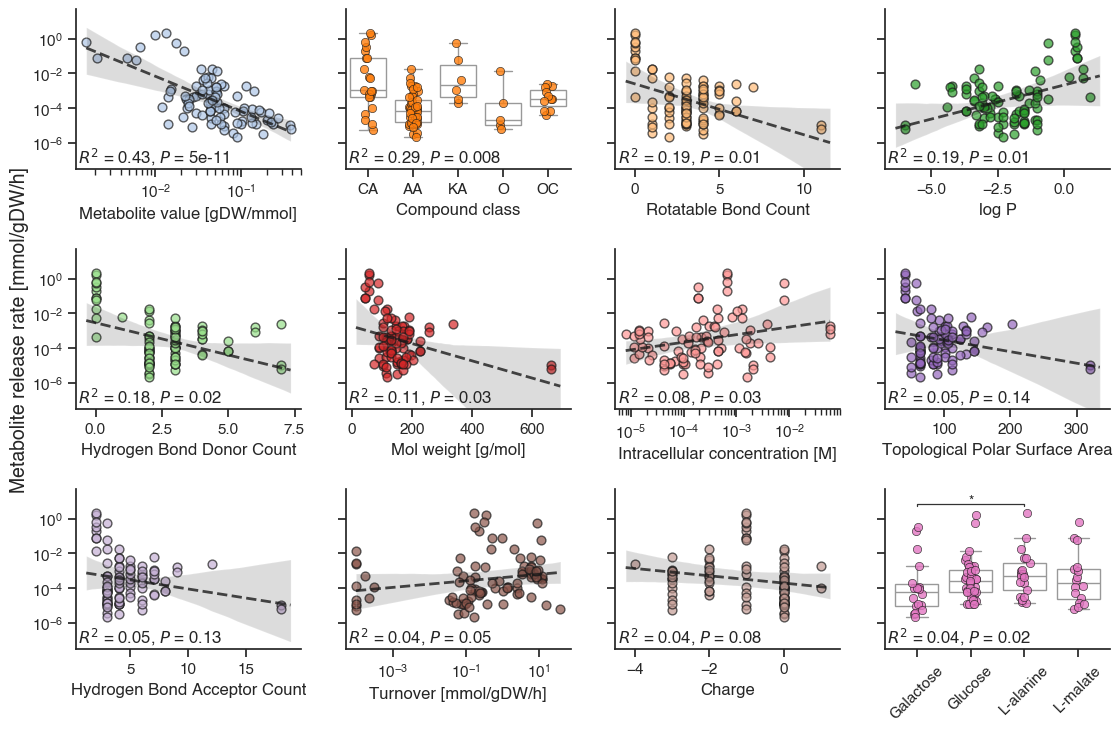

In [114]:
def fmt_p(p):
    return f"{p:.2f}" if p >= 0.01 else (f"{p:.3f}" if p >= 0.001 else f"{p:.0e}")

fig, axes = plt.subplots(3,4, figsize = (11,8),sharey=True)
axes = axes.flatten()

r2_dict = df_r2.set_index('Parameter')['Variability explained'].to_dict()

cmap = plt.get_cmap('tab20')
color_dict = {xaxis:cmap(i) for i, xaxis in enumerate(df_r2.Parameter)}
# bar_colors = [color_dict[x] for x in df_r2.Parameter.values]

plot_parameters = [x for x in df_r2.Parameter if not '+' in x]
yaxis = 'Rate [mmol/gDW/h]'
logyaxis = 'log10(Rate [mmol/gDW/h])'

not_log_xaxis_dict = {
    'log10(Intracellular conc. [M])': 'Intracellular concentration [M]',
    'log10(Turnover [mmol/gDW/h])': 'Turnover [mmol/gDW/h]',
    'log10(Metabolite value [gDW/mmol])': 'Metabolite value [gDW/mmol]',
}
columns = [logyaxis, yaxis, 'Metabolite'] + plot_parameters + list(not_log_xaxis_dict.values())
lindf_p = df_mean_ecoli[columns].copy()

lindf_p.fillna({'log10(Turnover [mmol/gDW/h])':-4}, inplace = True)
lindf_p.fillna({'Turnover [mmol/gDW/h]': 1e-4}, inplace=True)
lindf_p.replace({'Turnover [mmol/gDW/h]': {0: 1e-4}}, inplace = True)

lindf_p.dropna(inplace=True)

for i, xaxis in enumerate(plot_parameters):
    if i >= 12:
        break
    ax = axes[i]
        
    print(xaxis)
    color = color_dict[xaxis]
    # idx = (df_mean.Species=='E. coli')&(df_mean.Dataset != 'Vila-23')&df_mean[[xaxis,logyaxis]].notna().all(axis = 1)
    if xaxis in ['Compound class', 'Carbon source']:
        # --- Statistical test: OLS with SEs clustered by metabolite ---
        d = (lindf_p[[logyaxis, xaxis, "Metabolite"]]
            .rename(columns={logyaxis: "y", xaxis: "g"})
            .dropna())
        d["g"] = d["g"].astype(str)

        fit = sm.ols("y ~ C(g)", data=d).fit(
            cov_type="cluster", cov_kwds={"groups": d["Metabolite"]}
        )
        print(f"{xaxis}: overall cluster-robust Wald test, P = {fit.f_pvalue:.2g}")

        # Pairwise Wald tests with BH correction
        pw = fit.t_test_pairwise("C(g)", method="fdr_bh").result_frame
        padj_col = [c for c in pw.columns if c.startswith("pvalue-")][0]
        print(pw[["coef", "P>|z|", padj_col]])

        def pair_p(a, b):
            a, b = str(a), str(b)
            for key in (f"{b}-{a}", f"{a}-{b}"):
                if key in pw.index:
                    return pw.at[key, padj_col]
            raise KeyError((a, b))

        compound_classes = list(lindf_p[xaxis].unique())
        pairs = [(g1, g2) for j, g1 in enumerate(compound_classes)
                        for g2 in compound_classes[j + 1:]]
        p_values = [pair_p(*pair) for pair in pairs]
        # # Statistical test
        # data = []
        # # compound_classes = df_mean.loc[idx, xaxis].unique()
        # compound_classes = lindf_p[xaxis].unique()
        # for c1 in compound_classes:
        #     # dfmc = df_mean.loc[idx&(df_mean_ecoli[xaxis] == c1)]
        #     dfmc = lindf_p.loc[lindf_p[xaxis] == c1]
        #     data.append(dfmc[logyaxis].values)
        # # Perform one-way ANOVA
        # f_stat, p_value = st.kruskal(*data)

        # # Print the results
        # print(f"F-statistic: {f_stat}")
        # print(f"P-value: {p_value}")
        
        # # Posthoc analyses
        # posthoc_results = posthoc_conover(lindf_p, val_col=logyaxis, group_col=xaxis, p_adjust='fdr_bh')#'bonferroni'
        # print(posthoc_results)

        # # Define pairs for comparisons
        # pairs = [(group1, group2) for j, group1 in enumerate(compound_classes) for group2 in compound_classes[j + 1:]]
        # p_values = [posthoc_results.at[pair[0], pair[1]]for pair in pairs]
        
        
        sns.boxplot(data = lindf_p, x = xaxis, y = yaxis, color='w', 
                    ax = ax, fliersize=0, log_scale= True)
        sns.stripplot(data = lindf_p, x = xaxis, y = yaxis, 
                      size= 6, edgecolor='k',  linewidth=0.5,
                      color=color, ax = ax, alpha = 0.8, log_scale= True)
        
        # Add statistical annotations
        annotator = Annotator(ax, pairs, data=lindf_p, x=xaxis, y=logyaxis)
        annotator.configure(
            text_format="star",
            loc="inside",
            hide_non_significant=True,
            text_offset = -3,  # Adjust the text offset
            fontsize=10,
            line_width = 0.9,
            # use_fixed_offset=True,
            
            # line_offset_to_group=0.01,  # Reduce the vertical offset of the lines
            line_height=0.01           # Reduce the height of the brackets
        )
        
        annotator.set_pvalues_and_annotate(p_values)
        ax.annotate(f'$R^2$ = {r2_dict[xaxis]:.2f}, $P$ = {fmt_p(fit.f_pvalue)}', (0.01, 0.01), xycoords = 'axes fraction', ha = 'left', va = 'bottom')
        # ax.annotate(f'$R^2$ = {r2_dict[xaxis]:.2f}', (0.01, 0.01), xycoords = 'axes fraction', ha = 'left', va = 'bottom')

        if xaxis == 'Compound class':
            ax.set_xticklabels([short_cclass[x.get_text()] for x in ax.get_xticklabels()],size = 11)
        else:
            ax.set_xticklabels([x.get_text() for x in ax.get_xticklabels()],size = 11, rotation = 45)
            ax.set_xlabel('')
    else:
        if xaxis[:5] == 'log10':
            not_logxaxis = not_log_xaxis_dict[xaxis]
            sns.scatterplot(data = lindf_p, x = not_logxaxis, y = yaxis,
                            color=color, ax = ax, edgecolor='k', s=40, alpha=0.7, 
                            linewidth=1,
                            )
            
            # fit regression model
            ax.set_xscale('log')
            
            # rp = sns.regression._RegressionPlotter(df_mean.loc[idx, xaxis], df_mean.loc[idx, logyaxis])
            rp = sns.regression._RegressionPlotter(lindf_p[xaxis], lindf_p[logyaxis], units=lindf_p["Metabolite"])
            
            xrange = lindf_p[xaxis].min(), lindf_p[xaxis].max()
            grid, yhat, err_bands = rp.fit_regression(x_range=xrange)
            # plot regression line with restored Y values
            grid = np.power(10, grid)
            

        else:
            sns.scatterplot(data = lindf_p, x = xaxis, y = yaxis,
                            color=color, ax = ax, edgecolor='k', s=40, alpha=0.7, 
                            linewidth=1)
            rp = sns.regression._RegressionPlotter(lindf_p[xaxis], lindf_p[logyaxis], units=lindf_p["Metabolite"])
        
            grid, yhat, err_bands = rp.fit_regression(ax=ax)
        line, = ax.plot(grid, np.power(10, yhat), c = 'k', ls = '--', lw = 2, zorder=10, alpha = 0.8)
        # plot error boundaries
        ax.fill_between(
            grid,
            *[np.power(10, b) for b in err_bands],
            facecolor=line.get_color(),
            alpha=.15,
        )
        ax.set_yscale('log')
        # create regression plotter object with log’d Y values
        
        d = lindf_p[[xaxis, logyaxis, "Metabolite"]].dropna().rename(columns={xaxis: "x", logyaxis: "y"})
        fit = sm.ols("y ~ x", data=d).fit(
                    cov_type="cluster", cov_kwds={"groups": d["Metabolite"]}
                    )
        pvalue = fit.pvalues["x"]
        # slope, intercept = fit.params[1], fit.params[0]
        
        rsq = fit.rsquared
        _, _, _, pvalue_old, _ = linregress(lindf_p[xaxis].values, lindf_p[logyaxis].values)
        # ax.annotate(fr'$\rho$ = {rvalue:.2f}', (0.6, 0.9), xycoords = 'axes fraction')
        print(xaxis, r2_dict[xaxis], rsq, f'p_value: {pvalue:.1e}, p_value_old: {pvalue_old:.1e}')
        ax.annotate(f'$R^2$ = {r2_dict[xaxis]:.2f}, $P$ = {fmt_p(pvalue)}', (0.01, 0.01), xycoords = 'axes fraction', ha = 'left', va = 'bottom')
        ax.set_xlabel(ax.get_xlabel().replace('log10', r'$\rm{log_{10}}$'),size = 12)
    ax.set_ylabel("")

    
    # ax.annotate(fr'$R^2$ = {rvalue**2:.2f}', (0.62, 0.7), xycoords = 'axes fraction')
    
fig.supylabel(r'Metabolite release rate [mmol/gDW/h]', size = 14)

plt.ylim(3e-8, 5e1)
sns.despine()
plt.subplots_adjust(left = 0.08, wspace=0.2, hspace=0.5, right = 1.02, top = 0.9, bottom = 0.1)
plt.savefig(figure_folder/'correlations_different_factors_ecoli_standards.pdf', bbox_inches='tight')
# corr_data = df_mean.loc[df_mean.Species=='E. coli',['log10(Metabolite value [gDW/mmol])', 'log10(Rate [mmol/gDW/h])']]
# corr_data = corr_data.loc[~corr_data.isna().any(axis = 1)]

In [115]:
wide = lindf_p.pivot_table(index="Metabolite", columns="Carbon source", values=logyaxis)
both = wide[["Galactose", "L-alanine"]].dropna()
print(len(both), st.wilcoxon(both["Galactose"], both["L-alanine"]))
(both["Galactose"] < both["L-alanine"]).sum(), (both["Galactose"] - both["L-alanine"]).median()

15 WilcoxonResult(statistic=np.float64(22.0), pvalue=np.float64(0.0301513671875))


(np.int64(10), -0.675482736444402)

In [116]:
print(len(lindf), lindf["Metabolite"].nunique())
print(len(lindf_p), lindf_p["Metabolite"].nunique())
print(set(lindf["Metabolite"]) - set(lindf_p["Metabolite"]))   # which ones are missing

92 48
92 48
set()


## Add supplemental figure with metabolite values for the different classes

n = 153 observations of 53 metabolites
Overall cluster-robust Wald test: P = 3.3e-08
                                                 coef         P>|z|  \
Carboxylic acids-Amino acids                -0.453654  7.712168e-04   
Keto / hydroxy acids-Amino acids            -0.461495  1.977274e-08   
Organooxygen compounds-Amino acids          -0.106426  2.493683e-01   
Other-Amino acids                            0.073034  7.106469e-01   
Keto / hydroxy acids-Carboxylic acids       -0.007841  9.498486e-01   
Organooxygen compounds-Carboxylic acids      0.347227  8.333503e-03   
Other-Carboxylic acids                       0.526688  1.571080e-02   
Organooxygen compounds-Keto / hydroxy acids  0.355069  3.661673e-06   
Other-Keto / hydroxy acids                   0.534530  4.904033e-03   
Other-Organooxygen compounds                 0.179461  3.564913e-01   

                                             pvalue-fdr_bh  
Carboxylic acids-Amino acids                  2.570723e-03  
Keto / hydr

/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/938396974.py:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([short_cclass[x.get_text()] for x in ax.get_xticklabels()], size=11)


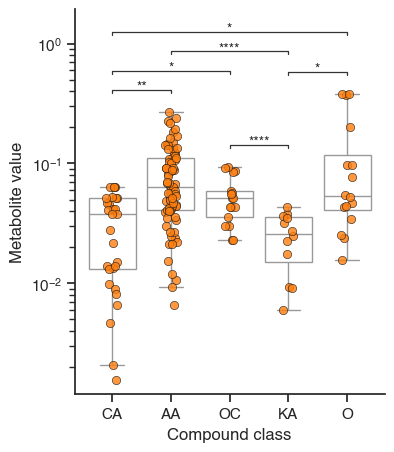

In [120]:
# --- Metabolite value by compound class (SEs clustered by metabolite) ---
fig, ax = plt.subplots(1, figsize=(4, 5))

cmap = plt.get_cmap('tab20')
xaxis = 'Compound class'
logyaxis = 'log10(Metabolite value [gDW/mmol])'
yaxis = 'Metabolite value [gDW/mmol]'

idx = (
    (df_mean.Species == 'E. coli')
    & (df_mean.Dataset != 'Vila-23')
    & df_mean[[xaxis, logyaxis]].notna().all(axis=1)
)
sub = df_mean.loc[idx].copy()

# --- Statistical test: OLS with standard errors clustered by metabolite ---
d = (sub[[logyaxis, xaxis, "Metabolite"]]
     .rename(columns={logyaxis: "y", xaxis: "g"})
     .dropna())
d["g"] = d["g"].astype(str)

fit = sm.ols("y ~ C(g)", data=d).fit(
    cov_type="cluster", cov_kwds={"groups": d["Metabolite"]}
)
print(f"n = {len(d)} observations of {d['Metabolite'].nunique()} metabolites")
print(f"Overall cluster-robust Wald test: P = {fit.f_pvalue:.2g}")

# Pairwise cluster-robust Wald tests with BH correction
pw = fit.t_test_pairwise("C(g)", method="fdr_bh").result_frame
padj_col = [c for c in pw.columns if c.startswith("pvalue-")][0]
print(pw[["coef", "P>|z|", padj_col]])

def pair_p(a, b):
    a, b = str(a), str(b)
    for key in (f"{b}-{a}", f"{a}-{b}"):
        if key in pw.index:
            return pw.at[key, padj_col]
    raise KeyError((a, b))

compound_classes = list(sub[xaxis].unique())
pairs = [(g1, g2) for j, g1 in enumerate(compound_classes)
                  for g2 in compound_classes[j + 1:]]
p_values = [pair_p(*pair) for pair in pairs]

# --- Plot ---
sns.boxplot(data=sub, x=xaxis, y=yaxis, color='w',
            ax=ax, fliersize=0, log_scale=True)
sns.stripplot(data=sub, x=xaxis, y=yaxis,
              color=cmap(2), ax=ax, alpha=0.8, edgecolor='k',
              linewidth=0.5, s=6, log_scale=True)

annotator = Annotator(ax, pairs, data=sub, x=xaxis, y=yaxis)
annotator.configure(
    text_format="star",
    loc="inside",
    hide_non_significant=True,
    text_offset=-3,
    fontsize=10,
    line_width=0.9,
    line_height=0.01,
)
annotator.set_pvalues_and_annotate(p_values)

ax.set_xticklabels([short_cclass[x.get_text()] for x in ax.get_xticklabels()], size=11)
ax.set_ylabel('Metabolite value', size=12)
sns.despine()

plt.savefig(figure_folder / 'metabolite_value_different_classes.pdf', bbox_inches='tight')

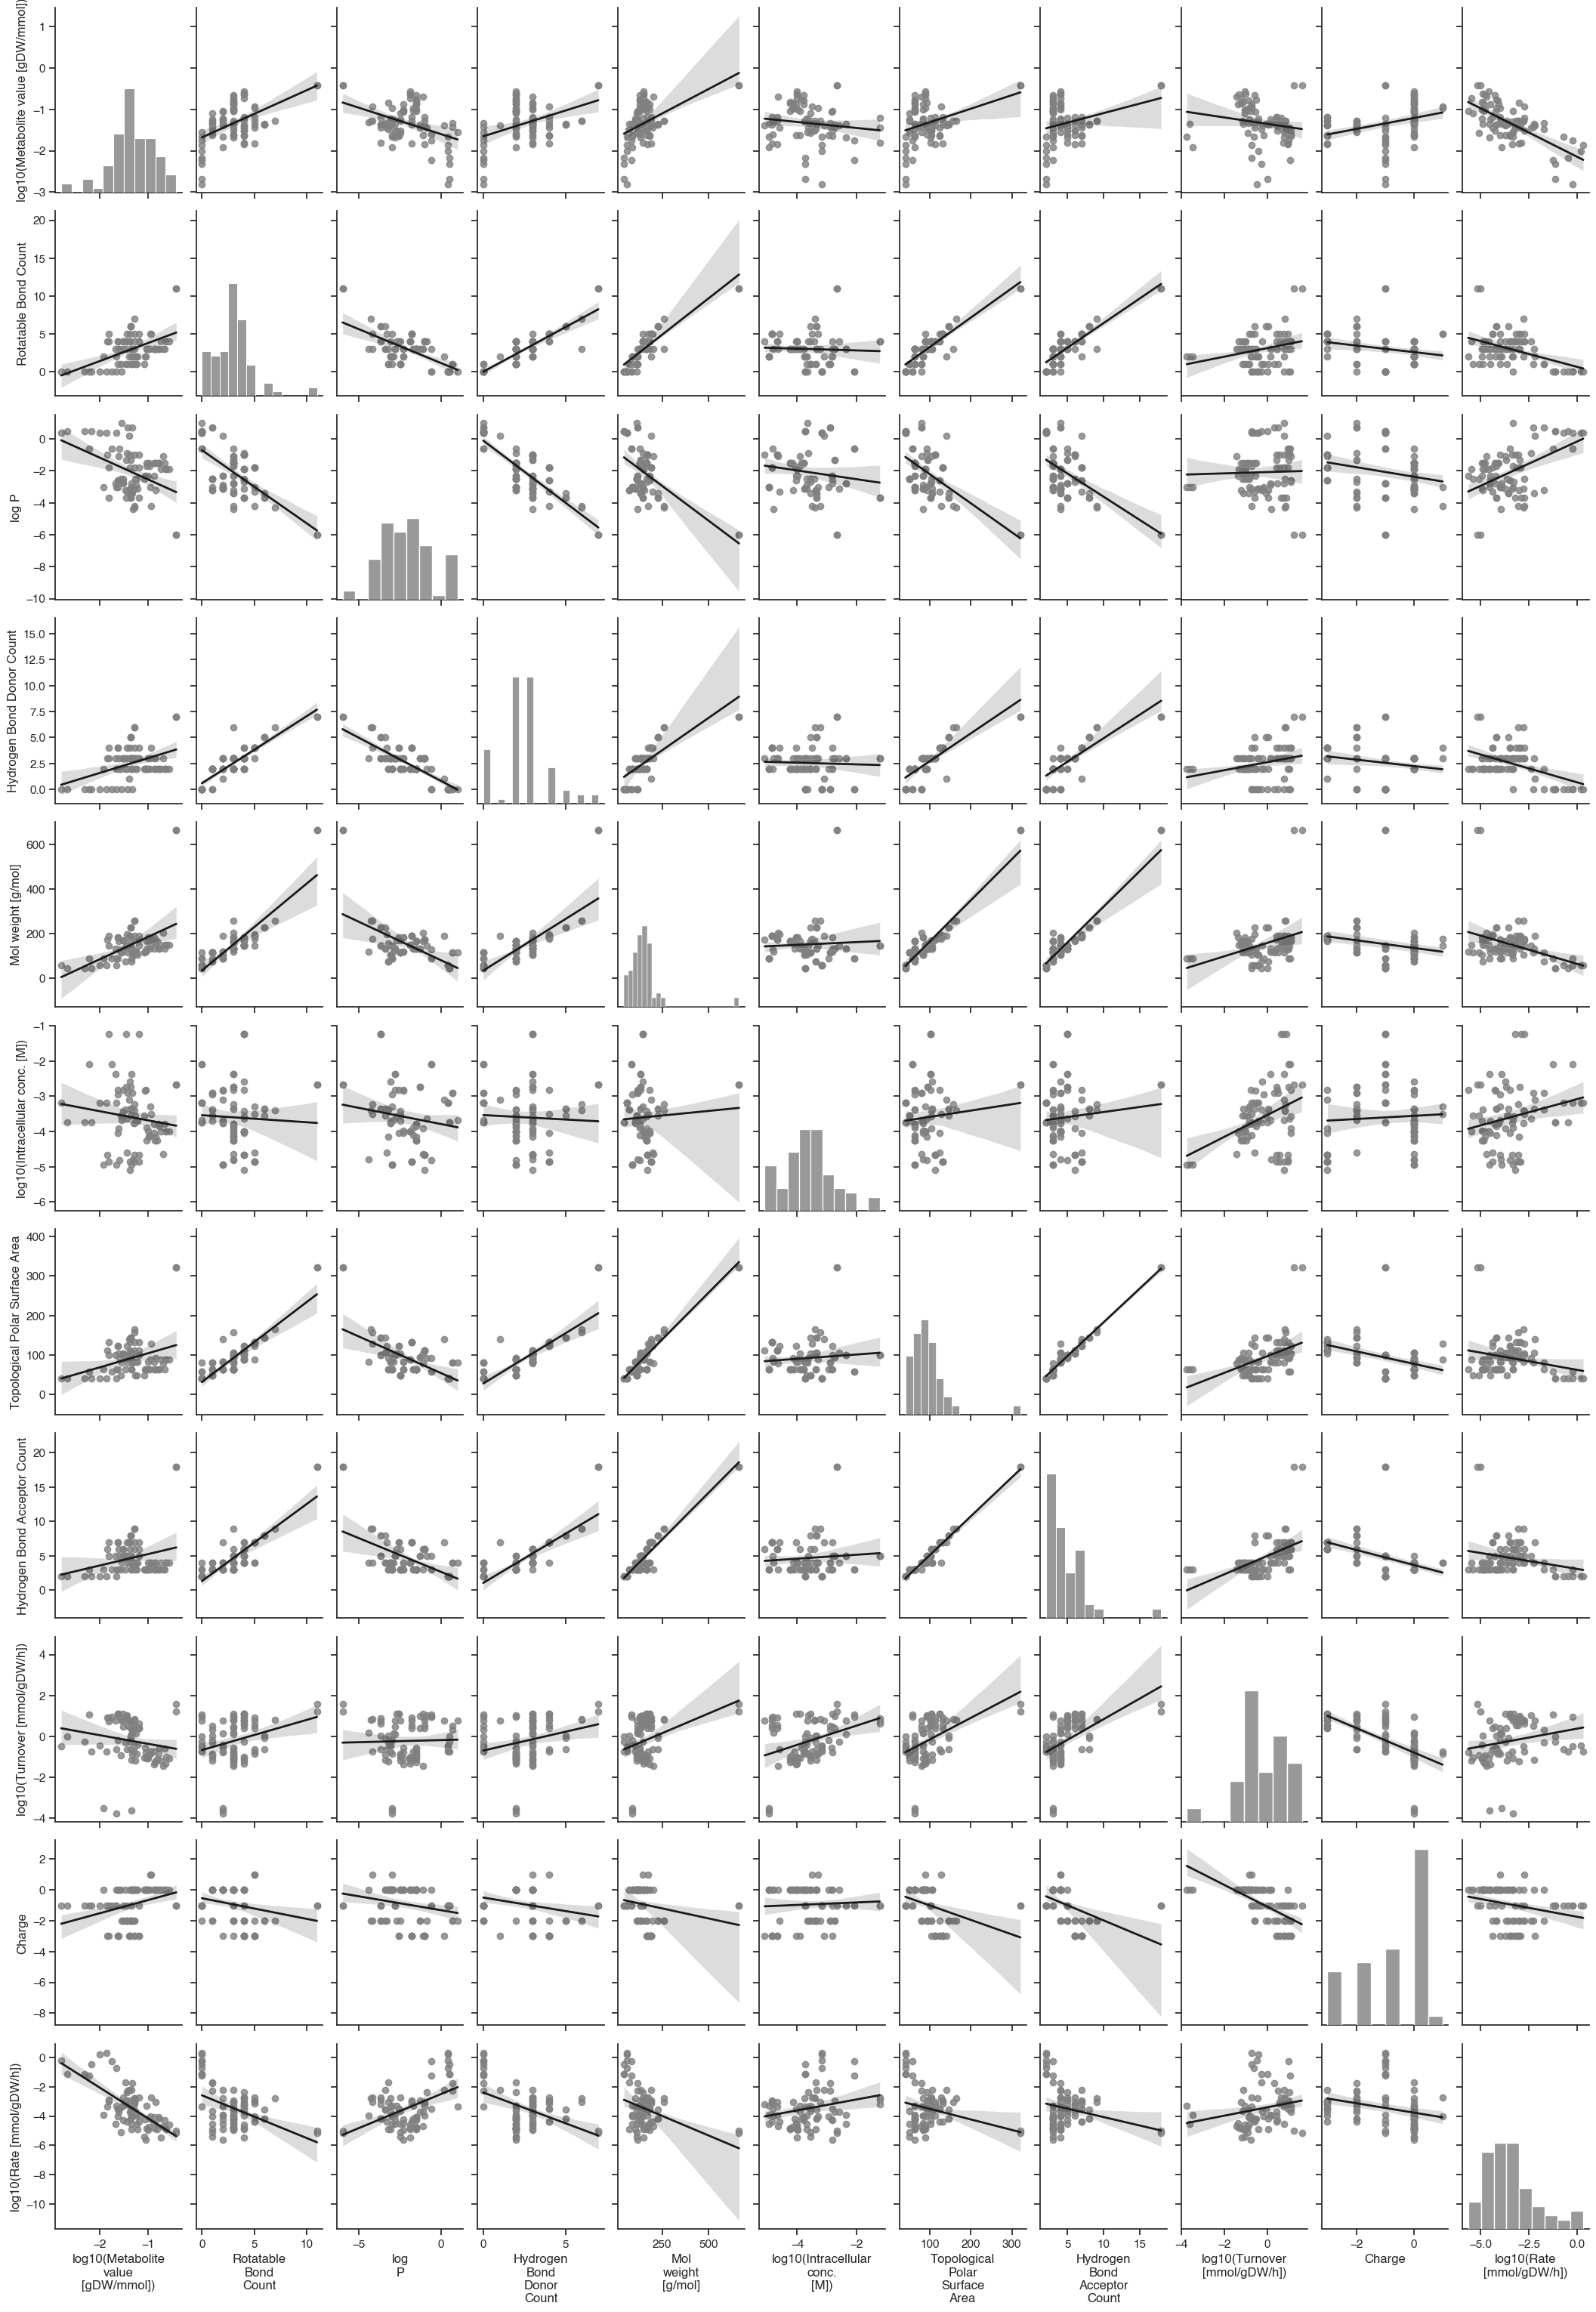

In [53]:
# Filter numeric columns from plot_parameters
numeric_plot_parameters = df_mean[plot_parameters].select_dtypes(include=['float64', 'int64']).columns.tolist() + ['log10(Rate [mmol/gDW/h])']

# Filter the DataFrame to exclude NaN values for the selected numeric parameters
idx = (df_mean.Species == 'E. coli') & (df_mean.Dataset != 'Vila-23') & df_mean[numeric_plot_parameters].notna().all(axis=1)

# Create the pairplot with regression for numeric parameters
pp = sns.pairplot(df_mean.loc[idx], vars=numeric_plot_parameters, kind='reg', aspect=0.7,
             plot_kws={
                "scatter_kws": {"color": "gray", "alpha": 0.8},  # Set scatter points to gray
                "line_kws": {"color": "k", "lw": 2},          # Set regression line to gray
                },
                 diag_kws={
                  "color": "gray",  # Set histogram bars to gray
                  "alpha": 0.8      # Adjust transparency of histogram bars
               })
# Wrap long x-axis labels into two lines
for ax in pp.axes[-1, :]:  # Iterate over the bottom row of axes
    ax.set_xlabel(ax.get_xlabel().replace(' ', '\n'), fontsize=12)  # Replace spaces with newlines
    ax.set_ylabel(ax.get_ylabel(), fontsize=12)
plt.subplots_adjust(top=1.1, right = 1.1)
plt.savefig(figure_folder/'pairplot_ecoli_standards.pdf', bbox_inches='tight')

In [54]:
posthoc_results.at['Amino acids', 'Keto / hydroxy acids']

np.float64(1.5129194090107796e-05)

## Supplemental linear models for each dataset / species

In [55]:
df_lm_dict = {}
for d in df_mean.Dataset.unique():
    dfd = df_mean.loc[df_mean.Dataset==d]
    for s in dfd.Species.unique():
        print(s)
        if s == 'C. glutamicum':
            continue
        dfs = dfd.loc[dfd.Species==s].copy()
        dfs.fillna({'log10(Turnover [mmol/gDW/h])':-4}, inplace = True)
        # Remove all nan columns
        dfs = dfs.loc[:, ~dfs.isna().all()]

        # Remove nan rows
        # dfs.dropna(inplace=True)
        
        lindfd = pd.DataFrame()
        for key, col_name in key_to_col.items():
            try:
                lindfd[key] = dfs[col_name]
            except KeyError:
                pass

        var_explained = {}
        for key, col_name in key_to_col.items():
            if col_name == 'log10(Rate [mmol/gDW/h])':
                continue
            elif (col_name=='log10(Intracellular conc. [M])') and (s != 'E. coli'):
                continue
            if col_name not in dfd.columns:
                continue
            res = sm.ols(formula=f"Y ~ {key}", data=lindfd).fit(missing='drop')
            var_explained[col_name] = res.rsquared
            print(key, col_name, f'R2: {res.rsquared:.2f}')
            # print(res.summary2())


        # var_explained['log10(MV) + log10(IC) + Charge + C class'] = res.rsquared
        # print(var_explained)
        df_r2 = pd.DataFrame(var_explained, index = ['Variability explained']).T.reset_index(names = 'Parameter').sort_values(by= 'Variability explained', ascending = False)
        df_lm_dict[f'{d}: {s}'] = df_r2
    

P. putida
B log10(Metabolite value [gDW/mmol]) R2: 0.45
C Charge R2: 0.01
D Mol weight [g/mol] R2: 0.10
E log P R2: 0.00
F log10(Turnover [mmol/gDW/h]) R2: 0.02
R Rotatable Bond Count R2: 0.06
S Hydrogen Bond Donor Count R2: 0.02
T Hydrogen Bond Acceptor Count R2: 0.09
U Topological Polar Surface Area R2: 0.11
G Compound class R2: 0.06
H Carbon source R2: 0.28
Pseudomonas
B log10(Metabolite value [gDW/mmol]) R2: 0.20
C Charge R2: 0.00
D Mol weight [g/mol] R2: 0.15
E log P R2: 0.05
F log10(Turnover [mmol/gDW/h]) R2: 0.00
R Rotatable Bond Count R2: 0.12
S Hydrogen Bond Donor Count R2: 0.12
T Hydrogen Bond Acceptor Count R2: 0.13
U Topological Polar Surface Area R2: 0.18
G Compound class R2: 0.10
H Carbon source R2: 0.17
E. coli
A log10(Intracellular conc. [M]) R2: 0.06
B log10(Metabolite value [gDW/mmol]) R2: 0.40
C Charge R2: 0.07
D Mol weight [g/mol] R2: 0.20
E log P R2: 0.13
F log10(Turnover [mmol/gDW/h]) R2: 0.04
R Rotatable Bond Count R2: 0.32
S Hydrogen Bond Donor Count R2: 0.28
T 

/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_80287/2574464775.py:31: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res = sm.ols(formula=f"Y ~ {key}", data=lindfd).fit(missing='drop')
/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_80287/2574464775.py:31: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res = sm.ols(formula=f"Y ~ {key}", data=lindfd).fit(missing='drop')


In [56]:
# Combine all DataFrames in df_lm_dict into a single DataFrame
big_df_r2 = pd.concat(df_lm_dict, names=['Dataset: Species/strain']).reset_index()

# Rename columns for clarity
big_df_r2.rename(columns={'level_1': 'Index'}, inplace=True)

# Display the resulting DataFrame
big_df_r2

,Dataset: Species/strain,Index,Parameter,Variability explained
0,Vila-23: P. putida,0,log10(Metabolite value [gDW/mmol]),0.445027
1,Vila-23: P. putida,10,Carbon source,0.276416
2,Vila-23: P. putida,8,Topological Polar Surface Area,0.109325
3,Vila-23: P. putida,2,Mol weight [g/mol],0.099002
4,Vila-23: P. putida,7,Hydrogen Bond Acceptor Count,0.086329
...,...,...,...,...
86,Paczia-12: S. cerevisiae,8,Topological Polar Surface Area,0.219908
87,Paczia-12: S. cerevisiae,7,Hydrogen Bond Acceptor Count,0.151215
88,Paczia-12: S. cerevisiae,4,log10(Turnover [mmol/gDW/h]),0.029218
89,Paczia-12: S. cerevisiae,1,Charge,0.002670


In [57]:
big_df_r2

,Dataset: Species/strain,Index,Parameter,Variability explained
0,Vila-23: P. putida,0,log10(Metabolite value [gDW/mmol]),0.445027
1,Vila-23: P. putida,10,Carbon source,0.276416
2,Vila-23: P. putida,8,Topological Polar Surface Area,0.109325
3,Vila-23: P. putida,2,Mol weight [g/mol],0.099002
4,Vila-23: P. putida,7,Hydrogen Bond Acceptor Count,0.086329
...,...,...,...,...
86,Paczia-12: S. cerevisiae,8,Topological Polar Surface Area,0.219908
87,Paczia-12: S. cerevisiae,7,Hydrogen Bond Acceptor Count,0.151215
88,Paczia-12: S. cerevisiae,4,log10(Turnover [mmol/gDW/h]),0.029218
89,Paczia-12: S. cerevisiae,1,Charge,0.002670


/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_80287/2276902653.py:55: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([short_labels.get(lbl.get_text(), lbl.get_text()) for lbl in ax.get_yticklabels()], fontsize=11)


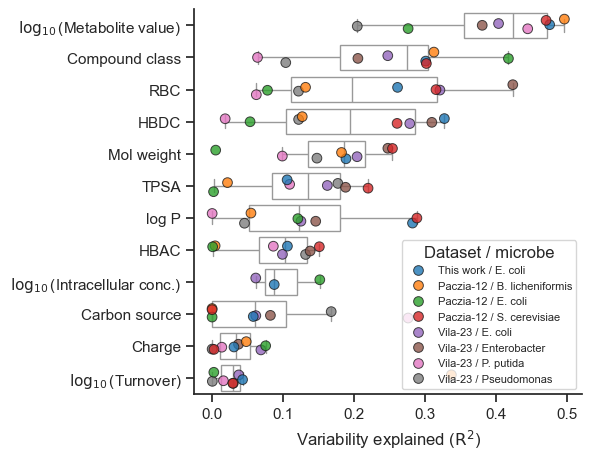

In [58]:
# Calculate the median of 'Variability explained' for each 'Parameter'
sns.set_theme(font_scale = 1, style = 'ticks')

big_df_r2['Dataset: Species/strain'] = big_df_r2['Dataset: Species/strain'].str.replace('SINTEF-23', 'This work')
big_df_r2['Dataset / microbe'] = big_df_r2['Dataset: Species/strain'].str.replace(': ', ' / ')
# Reorder the DataFrame based on the median order
big_df_r2['Parameter'] = pd.Categorical(big_df_r2['Parameter'])
big_df_r2['Parameter name'] = big_df_r2['Parameter'].str.replace(r' \[.*?\]', '', regex=True)
big_df_r2['Parameter name'] = big_df_r2['Parameter name'].str.replace('log10', r'$\log_{10}$', regex=False)
median_order = big_df_r2.groupby('Parameter name')['Variability explained'].median().sort_values(ascending=False)

dataset_order = ['This work / E. coli',
                'Paczia-12 / B. licheniformis',
                'Paczia-12 / E. coli',
                'Paczia-12 / S. cerevisiae',
                'Vila-23 / E. coli',
                'Vila-23 / Enterobacter', 
                'Vila-23 / P. putida', 
                'Vila-23 / Pseudomonas' ]
# Create the plot
fig, ax = plt.subplots(1, figsize=(5, 5))
ax = sns.boxplot(data=big_df_r2, x='Variability explained', y='Parameter name',
                 color='w', fliersize=0, order=median_order.index)
sns.stripplot(data=big_df_r2, x='Variability explained', y='Parameter name', hue='Dataset / microbe',
              hue_order= dataset_order,
              palette='tab10', legend=True, ax=ax, jitter=0.2, s=7, alpha=0.8,
              edgecolor='k', linewidth=0.7)

# Format the y-axis labels
# formatted_labels = [label.replace('log10', r'$\log_{10}$') for label in median_order.index]
# ax.set_yticklabels(formatted_labels, fontsize=10)

# Adjust legend
ax.set_xlabel(r"Variability explained ($\rm{R^2}$)")

sns.move_legend(ax, "lower right", bbox_to_anchor=(1, 0), title='Dataset / microbe', fontsize=8)
plt.ylabel('')

short_labels = {
    # '$\\log_{10}$(Metabolite value)': 'MV',
    # '$\\log_{10}$(Intracellular conc.)': 'IC',
    # '$\\log_{10}$(Turnover)': 'TO',
    # 'Mol weight': 'MW',
    # 'Charge': 'Chg',
    'Rotatable Bond Count': 'RBC',
    'Hydrogen Bond Donor Count': 'HBDC',
    'Hydrogen Bond Acceptor Count': 'HBAC',
    'Topological Polar Surface Area': 'TPSA',
    # 'Compound class': 'Class',
    # 'Carbon source': 'CS',
    # Add more as needed
}

# After plotting, set the y-axis tick labels:
ax.set_yticklabels([short_labels.get(lbl.get_text(), lbl.get_text()) for lbl in ax.get_yticklabels()], fontsize=11)
# plt.tight_layout()
sns.despine()

plt.savefig(figure_folder/'variability_explained_all_dataset.pdf', bbox_inches='tight')
# posthoc_conover(big_df_r2, val_col='Variability explained', group_col='Parameter name', p_adjust='fdr_bh')

In [59]:
big_df_r2['Dataset: Species/strain'].unique()

array(['Vila-23: P. putida', 'Vila-23: Pseudomonas', 'Vila-23: E. coli',
       'Vila-23: Enterobacter', 'This work: E. coli',
       'Paczia-12: B. licheniformis', 'Paczia-12: E. coli',
       'Paczia-12: S. cerevisiae'], dtype=object)

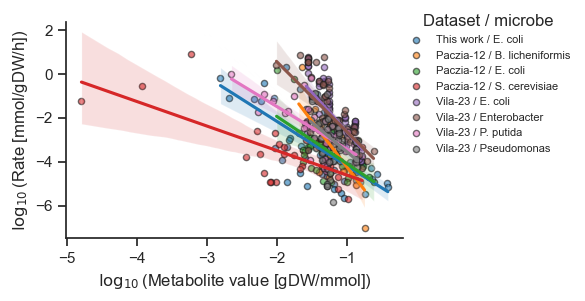

In [60]:
# Combine 'Dataset' and 'Species' into a single column
df_mean['Hue'] = df_mean['Dataset'] + " / " + df_mean['Species']
df_mean['Hue'] = df_mean['Hue'].str.replace('SINTEF-23', 'This work')

# Create the plot with the combined column as hue
g = sns.lmplot(
    data=df_mean.loc[df_mean.Species != 'C. glutamicum'],
    x='log10(Metabolite value [gDW/mmol])',
    y='log10(Rate [mmol/gDW/h])',
    hue='Hue',  # Use the combined column for hue
    hue_order=dataset_order,
    palette='tab10',
    height=3,
    aspect=1.5,
    scatter_kws={'s': 20, 'edgecolor': 'k', 'alpha': 0.6},
)
sns.move_legend(g, "upper right", bbox_to_anchor=(0.9, 1), title='Dataset / microbe', fontsize=8)
plt.xlabel(r'$\log_{10}$(Metabolite value [gDW/mmol])')
plt.ylabel(r'$\log_{10}$(Rate [mmol/gDW/h])')
plt.savefig(figure_folder / 'MV_vs_rate_all_species.pdf', bbox_inches='tight')

In [123]:

import statsmodels.api as smapi

def clustered_corr_p(x, y, groups):
    """P-value for Pearson r via OLS on z-scored variables, SEs clustered by metabolite."""
    xz = (x - x.mean()) / x.std()
    yz = (y - y.mean()) / y.std()
    X = smapi.add_constant(xz.values)
    fit = smapi.OLS(yz.values, X).fit(cov_type="cluster", cov_kwds={"groups": groups.values})
    return fit.pvalues[1]

def stars(p):
    if np.isnan(p) or p > 0.05:
        return ''
    if p > 0.01:
        return '*'
    if p > 0.001:
        return '**'
    if p > 0.0001:
        return '***'
    return '****'

def format_log10_label(label):
    return label.replace("log10", r"$\log_{10}$")

def correlation_clustermap(df, cols, outfile_stem):
    df = df[cols + ['Metabolite']]
    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
    groups_all = pd.Series(pd.factorize(df['Metabolite'])[0], index=df.index)

    correlation_matrix = df[numeric_cols].corr()

    p_values = pd.DataFrame(np.nan, index=numeric_cols, columns=numeric_cols)
    for a, b in itertools.combinations(numeric_cols, 2):
        ok = df[[a, b]].notna().all(axis=1)
        p = clustered_corr_p(df.loc[ok, a], df.loc[ok, b], groups_all[ok])
        p_values.loc[a, b] = p_values.loc[b, a] = p

    print(f"{outfile_stem}: n = {len(df)} rows, {df['Metabolite'].nunique()} metabolites")

    sns.set_theme(style="white")
    cm = sns.clustermap(correlation_matrix, cmap="coolwarm", center=0, annot=True,
                        fmt=".2f", linewidths=0.5, figsize=(10, 8), cbar_pos=None)

    rr, rc = cm.dendrogram_row.reordered_ind, cm.dendrogram_col.reordered_ind
    rcorr = correlation_matrix.iloc[rr, rc]
    rp = p_values.iloc[rr, rc]

    for i in range(rcorr.shape[0]):
        for j in range(rcorr.shape[1]):
            if i == j:
                continue
            color = 'w' if np.abs(rcorr.iloc[i, j]) > 0.5282 else 'k'
            cm.ax_heatmap.text(j + 0.5, i + 1, stars(rp.iloc[i, j]),
                               color=color, ha='center', va='center', fontsize=10)

    ax = cm.ax_heatmap
    ax.set_xticklabels([format_log10_label(t.get_text()) for t in ax.get_xticklabels()], rotation=90)
    ax.set_yticklabels([format_log10_label(t.get_text()) for t in ax.get_yticklabels()], rotation=0)

    plt.savefig(figure_folder / f'{outfile_stem}.pdf', bbox_inches='tight')
    plt.savefig(figure_folder / f'{outfile_stem}.png', bbox_inches='tight', dpi=300)
    plt.show()
    return correlation_matrix, p_values

In [147]:
df_mean.loc[mask_ecoli]

,Carbon source,Species,Metabolite,Dataset,Rate [mmol/gDW/h],Std. Err [mmol/gDW/h],Metabolite value [gDW/mmol],N carbons,Mol weight [g/mol],Turnover [mmol/gDW/h],...,Metabolite value [gDW/mmol C],Metabolite value [gDW/g],log10(Rate [mmol C/gDW/h]),log10(Rate [g/gDW/h]),log10(Metabolite value [gDW/mmol C]),log10(Metabolite value [gDW/g]),log10(Turnover [mmol/gDW/h]),Intracellular concentration [M],log10(Intracellular conc. [M]),Compound class
157,Galactose,E. coli,2-aminoisobutyrate,SINTEF-23,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
158,Galactose,E. coli,2-hydroxybutyrate,SINTEF-23,NaN,NaN,0.063612,4.0,103.096580,0.000000,...,0.015903,0.617015,NaN,NaN,-1.798520,-0.209704,NaN,NaN,NaN,NaN
159,Galactose,E. coli,2-hydroxyglutaric acid,SINTEF-23,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
160,Galactose,E. coli,3-(4-hydroxyphenyl)pyruvate,SINTEF-23,NaN,NaN,0.137453,9.0,179.149480,0.056003,...,0.015273,0.767252,NaN,NaN,-1.816089,-0.115062,-1.251792,NaN,NaN,NaN
161,Galactose,E. coli,3-hydroxyanthranilate,SINTEF-23,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
686,L-malate,E. coli,Urocanate,SINTEF-23,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
687,L-malate,E. coli,Valine,SINTEF-23,NaN,NaN,0.087400,5.0,117.146340,0.232753,...,0.017480,0.746077,NaN,NaN,-1.757458,-0.127216,-0.633105,0.00155,-2.80978,Amino acids
688,L-malate,E. coli,Xanthine,SINTEF-23,NaN,NaN,0.129054,5.0,152.110860,0.134052,...,0.025811,0.848420,NaN,NaN,-1.588199,-0.071389,-0.872728,NaN,NaN,NaN
689,L-malate,E. coli,Xanthosine,SINTEF-23,NaN,NaN,0.176151,10.0,284.225480,0.000000,...,0.017615,0.619758,NaN,NaN,-1.754115,-0.207778,NaN,NaN,NaN,NaN


clustermap_correlations_with_significance_ecoli_std: n = 333 rows, 113 metabolites


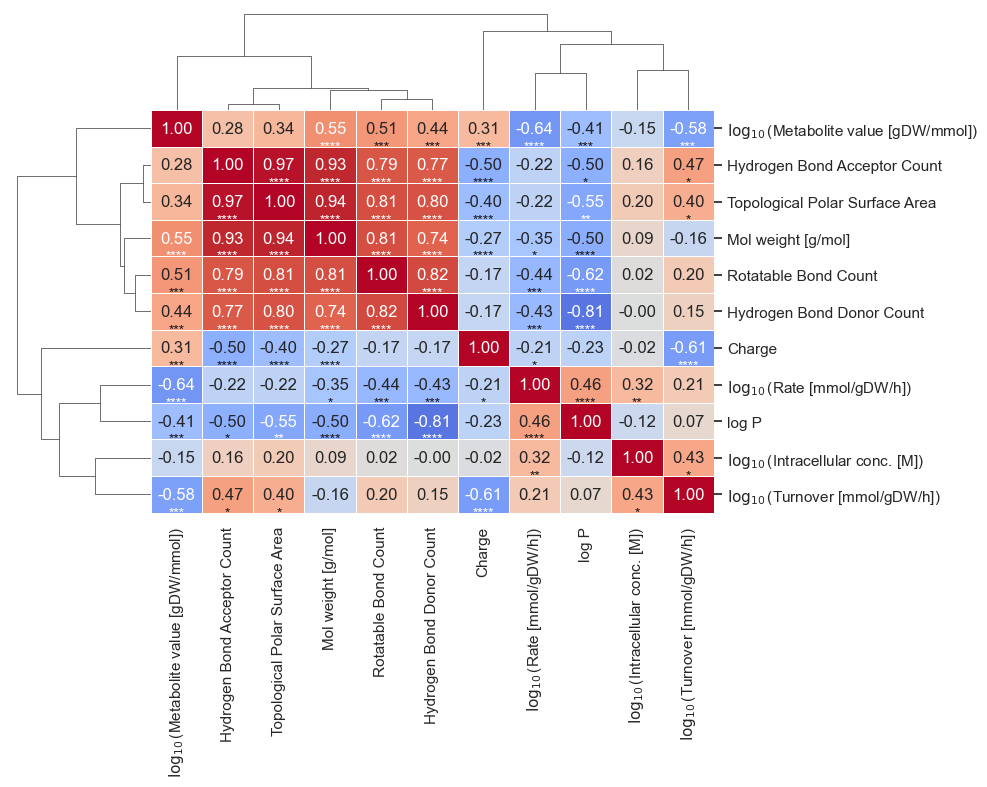

clustermap_correlations_with_significance_ecoli_lindf_std: n = 92 rows, 48 metabolites


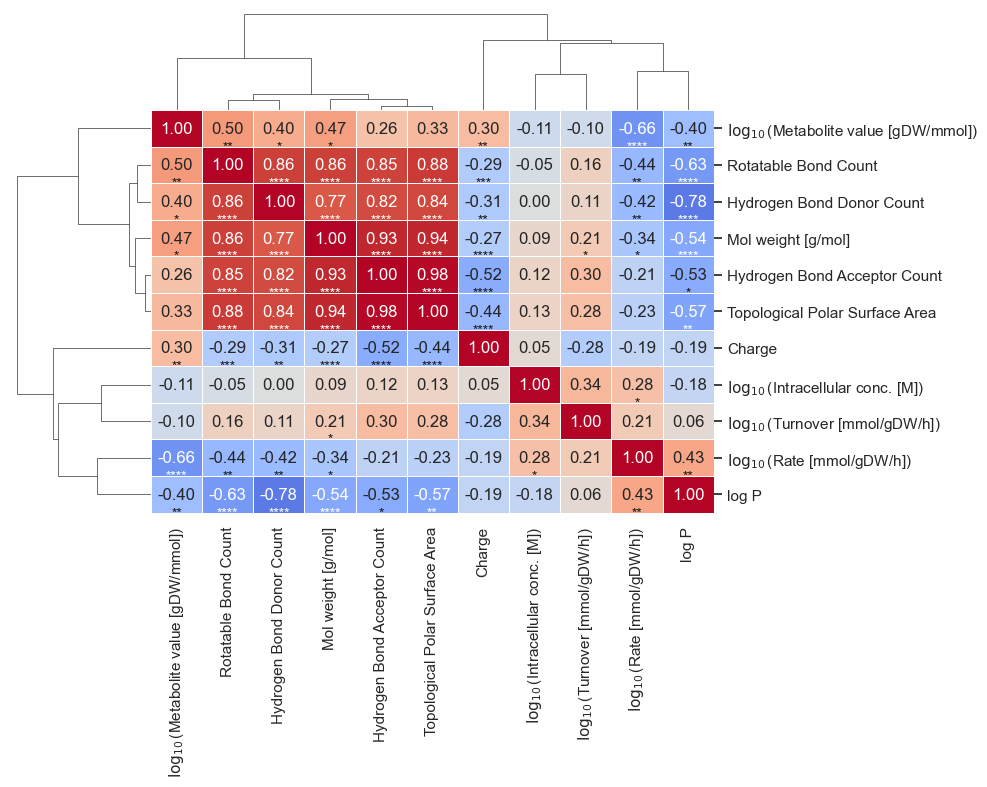

clustermap_correlations_with_significance: n = 726 rows, 119 metabolites


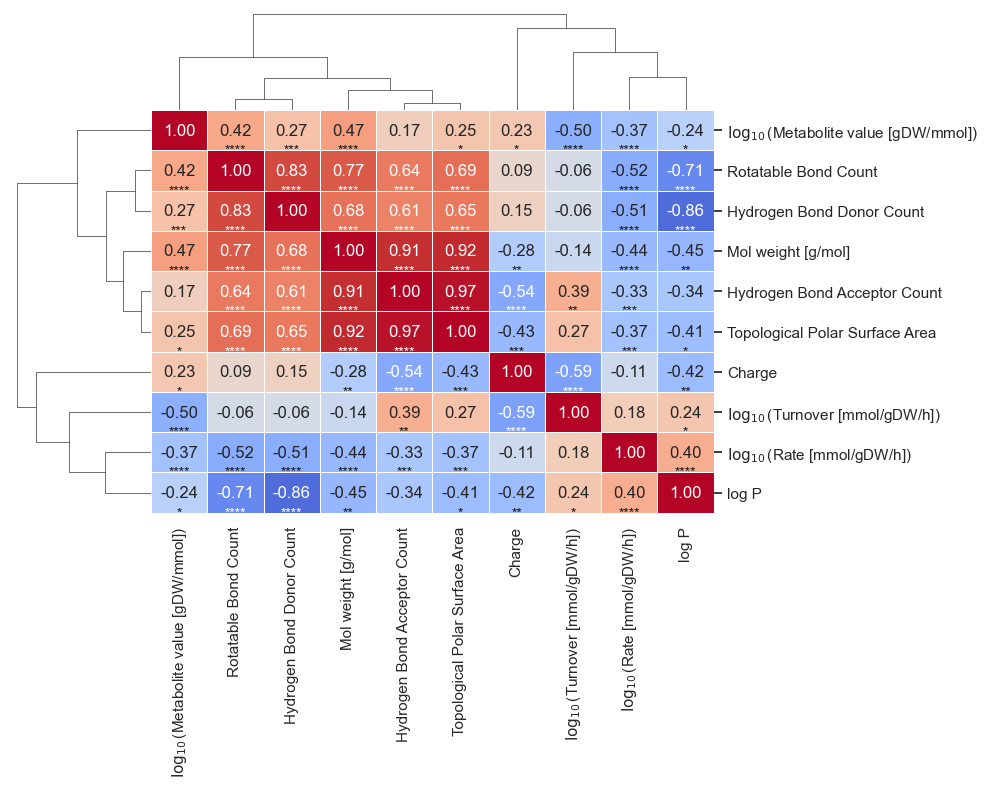

In [155]:
# E. coli only (this work + Paczia-12)
mask_ecoli = (df_mean['Species'] == 'E. coli') & (df_mean.Dataset != 'Vila-23')
corr_ecoli, p_ecoli = correlation_clustermap(
    df_mean.loc[mask_ecoli], list(key_to_col.values()),
    'clustermap_correlations_with_significance_ecoli_std')


lindf_for_corr = lindf.rename(columns=key_to_col).copy()
corr_lindf, p_lindf = correlation_clustermap(
    lindf_for_corr, list(key_to_col.values()),
    'clustermap_correlations_with_significance_ecoli_lindf_std')


# All species except C. glutamicum (no intracellular concentration)
cols_all = [x for x in key_to_col.values() if x != 'log10(Intracellular conc. [M])']
corr_all, p_all = correlation_clustermap(
    df_mean.loc[df_mean['Species'] != 'C. glutamicum'], cols_all,
    'clustermap_correlations_with_significance')

In [122]:

# df_filtered = df_mean.loc[((df_mean['Species'] == 'E. coli')&(df_mean.Dataset!='Vila-23')), [x for x in key_to_col.values()]]

# # Select only numeric columns for correlation
# numeric_cols = df_filtered.select_dtypes(include=['float64', 'int64'])

# # Compute the correlation matrix and p-values
# correlation_matrix = numeric_cols.corr()
# p_values = numeric_cols.corr(method=lambda x, y: st.pearsonr(x, y)[1])  # Compute p-values for correlations

# # Create a mask for significant correlations (e.g., p < 0.05)
# significance_mask = p_values < 0.05

# # Create the clustermap
# sns.set_theme(style="white")
# clustermap = sns.clustermap(
#     correlation_matrix,
#     cmap="coolwarm",
#     center=0,
#     annot=True,  # Add correlation values to the heatmap
#     fmt=".2f",   # Format for annotations
#     linewidths=0.5,
#     figsize=(10, 8),
#     cbar_pos=None
# )

# # Get the reordered indices from the clustermap
# reordered_rows = clustermap.dendrogram_row.reordered_ind
# reordered_cols = clustermap.dendrogram_col.reordered_ind

# # Reorder the correlation matrix and p-values to match the clustermap
# reordered_corr = correlation_matrix.iloc[reordered_rows, reordered_cols]
# reordered_pvals = p_values.iloc[reordered_rows, reordered_cols]

# # Add stars for significant correlations
# for i in range(reordered_corr.shape[0]):
#     for j in range(reordered_corr.shape[1]):
#         # print(i, j, p_values.iloc[i, j]) 
#         if i == j:
#             continue
#         if reordered_pvals.iloc[i, j] > 0.05:  # Adjust the threshold as needed
#             text = ''
#         elif 0.01 < reordered_pvals.iloc[i, j] < 0.05:
#             text = '*'
#         elif 0.001 < reordered_pvals.iloc[i, j] < 0.01:
#             text = '**'
#         elif 0.0001 < reordered_pvals.iloc[i, j] < 0.001:
#             text = '***'
#         else:
#             text = '****'

#         value = reordered_corr.iloc[i, j]

#         # Determine the color of the annotation based on the correlation value
#         if np.abs(value) > 0.5282:
#             color = 'w'
#         else:
#             color = 'k'

#         # Add the annotation at the correct position
#         clustermap.ax_heatmap.text(
#             j+0.5, i+1, text, color=color, ha='center', va='center', fontsize=10
#         )
# def format_log10_label(label):
#     return label.replace("log10", r"$\log_{10}$")

# heatmap_ax = clustermap.ax_heatmap
# heatmap_ax.set_xticklabels(
#     [format_log10_label(tick.get_text()) for tick in heatmap_ax.get_xticklabels()],
#     rotation=90,
# )
# heatmap_ax.set_yticklabels(
#     [format_log10_label(tick.get_text()) for tick in heatmap_ax.get_yticklabels()],
#     rotation=0,
# )
# plt.savefig(figure_folder / 'clustermap_correlations_with_significance_ecoli_std.pdf', bbox_inches='tight')
# plt.savefig(figure_folder / 'clustermap_correlations_with_significance_ecoli_std.png', bbox_inches='tight', dpi=300)
# # Show the plot
# plt.show()

In [125]:

# # Filter out rows where the species is 'C. glutamicum'
# cols = [x for x in key_to_col.values() if x not in ['log10(Intracellular conc. [M])']]
# df_filtered = df_mean.loc[df_mean['Species'] != 'C. glutamicum', cols]

# # Select only numeric columns for correlation
# numeric_cols = df_filtered.select_dtypes(include=['float64', 'int64'])

# # Compute the correlation matrix and p-values
# correlation_matrix = numeric_cols.corr()
# p_values = numeric_cols.corr(method=lambda x, y: st.pearsonr(x, y)[1])  # Compute p-values for correlations

# # Create a mask for significant correlations (e.g., p < 0.05)
# significance_mask = p_values < 0.05

# # Create the clustermap
# sns.set_theme(style="white")
# clustermap = sns.clustermap(
#     correlation_matrix,
#     cmap="coolwarm",
#     center=0,
#     annot=True,  # Add correlation values to the heatmap
#     fmt=".2f",   # Format for annotations
#     linewidths=0.5,
#     figsize=(10, 8),
#     cbar_pos=None
# )

# # Get the reordered indices from the clustermap
# reordered_rows = clustermap.dendrogram_row.reordered_ind
# reordered_cols = clustermap.dendrogram_col.reordered_ind

# # Reorder the correlation matrix and p-values to match the clustermap
# reordered_corr = correlation_matrix.iloc[reordered_rows, reordered_cols]
# reordered_pvals = p_values.iloc[reordered_rows, reordered_cols]

# # Add stars for significant correlations
# for i in range(reordered_corr.shape[0]):
#     for j in range(reordered_corr.shape[1]):
#         # print(i, j, p_values.iloc[i, j]) 
#         if i == j:
#             continue
#         if reordered_pvals.iloc[i, j] > 0.05:  # Adjust the threshold as needed
#             text = ''
#         elif 0.01 < reordered_pvals.iloc[i, j] < 0.05:
#             text = '*'
#         elif 0.001 < reordered_pvals.iloc[i, j] < 0.01:
#             text = '**'
#         elif 0.0001 < reordered_pvals.iloc[i, j] < 0.001:
#             text = '***'
#         else:
#             text = '****'

#         value = reordered_corr.iloc[i, j]

#         # Determine the color of the annotation based on the correlation value
#         if np.abs(value) > 0.5282:
#             color = 'w'
#         else:
#             color = 'k'

#         # Add the annotation at the correct position
#         clustermap.ax_heatmap.text(
#             j+0.5, i+1, text, color=color, ha='center', va='center', fontsize=10
#         )
# def format_log10_label(label):
#     return label.replace("log10", r"$\log_{10}$")

# heatmap_ax = clustermap.ax_heatmap
# heatmap_ax.set_xticklabels(
#     [format_log10_label(tick.get_text()) for tick in heatmap_ax.get_xticklabels()],
#     rotation=90,
# )
# heatmap_ax.set_yticklabels(
#     [format_log10_label(tick.get_text()) for tick in heatmap_ax.get_yticklabels()],
#     rotation=0,
# )

# plt.savefig(figure_folder / 'clustermap_correlations_with_significance.pdf', bbox_inches='tight')
# # Show the plot
# plt.show()

# Check intracellular concentration and parameters related to diffusion across the cell membrane

In [126]:
from statsmodels.stats.multitest import multipletests

descriptor_cols = {
    "Charge": "C",
    "Mol weight": "D",
    "log P": "E",
    "Rotatable Bond Count": "R",
    "Hydrogen Bond Donor Count": "S",
    "Hydrogen Bond Acceptor Count": "T",
    "Topological Polar Surface Area": "U",
}

results = []
base = lindf.dropna(subset=["Y", "A"])

for descriptor, d in descriptor_cols.items():
    columns = ["Y", "A", d]
    data = base[columns + ["Metabolite"]].copy()
    data[columns] = data[columns].apply(pd.to_numeric, errors="coerce")
    data = data.replace([np.inf, -np.inf], np.nan).dropna(subset=columns)

    conc_sd = data["A"].std(ddof=0)
    desc_sd = data[d].std(ddof=0)
    if len(data) == 0 or conc_sd == 0 or desc_sd == 0:
        results.append({"descriptor": descriptor, "n": len(data),
                        "status": "skipped: no usable variation"})
        continue

    data["conc_z"] = (data["A"] - data["A"].mean()) / conc_sd
    data["d_z"] = (data[d] - data[d].mean()) / desc_sd

    fit_kw = dict(cov_type="cluster", cov_kwds={"groups": data["Metabolite"]})
    full = sm.ols("Y ~ conc_z * d_z", data=data).fit(**fit_kw)
    reduced = sm.ols("Y ~ conc_z + d_z", data=data).fit(**fit_kw)

    ci = full.conf_int().loc["conc_z:d_z"]
    results.append({
        "descriptor": descriptor,
        "n": int(full.nobs),
        "n_metabolites": data["Metabolite"].nunique(),
        "interaction_estimate": full.params["conc_z:d_z"],
        "ci_low": ci[0],
        "ci_high": ci[1],
        "interaction_p": full.pvalues["conc_z:d_z"],
        "delta_BIC_full_minus_reduced": full.bic - reduced.bic,
        "status": "ok",
    })

interaction_results = pd.DataFrame(results)
ok = interaction_results["status"] == "ok"
interaction_results.loc[ok, "interaction_p_adj"] = multipletests(
    interaction_results.loc[ok, "interaction_p"], method="fdr_bh")[1]
interaction_results

,descriptor,n,n_metabolites,interaction_estimate,ci_low,ci_high,interaction_p,delta_BIC_full_minus_reduced,status,interaction_p_adj
0,Charge,92,48,-0.044803,-0.263835,0.174229,0.688485,4.429984,ok,0.688485
1,Mol weight,92,48,0.144947,-0.408094,0.697988,0.607471,4.004313,ok,0.688485
2,log P,92,48,0.261663,-0.037441,0.560768,0.086415,0.412845,ok,0.212285
3,Rotatable Bond Count,92,48,-0.261873,-0.693516,0.169770,0.234405,1.811121,ok,0.328167
4,Hydrogen Bond Donor Count,92,48,-0.308853,-0.751433,0.133727,0.171389,0.656564,ok,0.299930
5,Hydrogen Bond Acceptor Count,92,48,-0.315959,-0.673200,0.041281,0.083011,0.913444,ok,0.212285
6,Topological Polar Surface Area,92,48,-0.338245,-0.730463,0.053973,0.090979,0.580203,ok,0.212285


In [127]:
lindf['Metabolite'].nunique()

48

In [74]:
results_df = pd.DataFrame(results)
results_df

,descriptor,n,interaction_estimate,interaction_p,interaction_F,delta_BIC_full_minus_reduced,status
0,Charge,92,-0.044803,0.767617,0.087857,4.429984,ok
1,Mol weight,92,0.144947,0.482959,0.496371,4.004313,ok
2,log P,92,0.261663,0.048054,4.019384,0.412845,ok
3,Rotatable Bond Count,92,-0.261873,0.108348,2.631388,1.811121,ok
4,Hydrogen Bond Donor Count,92,-0.308853,0.055191,3.775935,0.656564,ok
5,Hydrogen Bond Acceptor Count,92,-0.315959,0.063946,3.520039,0.913444,ok
6,Topological Polar Surface Area,92,-0.338245,0.052841,3.852143,0.580203,ok


# Leave one out - random model

In [128]:
sns.set_theme(style = 'ticks', font_scale = 1)

## For CS

In [129]:
# Prepare random values
values = [1,2,3,4]
counts = lindf3['H'].value_counts().values
random_assignments = np.repeat(values, counts)

In [130]:
# cs_list = df_mean_ecoli['Carbon source'].unique()
lindf3 = lindf.copy()
lindf3.sort_values(by='H', inplace=True)
lindf3['G'] = pd.Categorical(lindf3['G'], categories=lindf3.G.unique())
# Add random grouping variable
# lindf3['Group'] = np.random.choice([1,2,3,4], size=len(lindf3), replace=True)
N_perm = 10000
r2_random = np.zeros(N_perm)
full_model =  sm.ols(formula="Y ~ A + B + G + C", data=lindf3)
full_res = full_model.fit()

for n in range(N_perm):
    np.random.shuffle(random_assignments)
    lindf3['Group'] = random_assignments

    
    y_preds2 = []
    y_vals2 = []
    for g in [1,2,3,4]:
        cidx = lindf3['Group']== g # "Carbon source" is represented by H in this df
        train_model = sm.ols(formula="Y ~ A + B + G + C", data=lindf3.loc[~cidx])
        train_res = train_model.fit()
        yp = train_res.predict(lindf3.loc[cidx, ['A', 'B', 'G', 'C']])
        y_vals2 += list(lindf3.loc[cidx, 'Y'].values)
        y_preds2 += list(yp)
        
    y_preds_arr2 = np.array(y_preds2)
    y_vals_arr2 = np.array(y_vals2)
    SSres = np.sum((y_preds_arr2-y_vals_arr2)**2)
    SStot = np.sum((y_vals_arr2-np.mean(y_vals_arr2))**2)
    R2 = 1-(SSres/SStot)
    r2_random[n] = R2

/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/3491863928.py:22: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  train_res = train_model.fit()
/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/3491863928.py:22: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  train_res = train_model.fit()
/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/3491863928.py:22: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  train_res = train_model.fit()
/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/3491863928.py:22: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  train_res = train_model.fit()
/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_19957/3491863928.py:22: SingularMatrixWar

In [131]:
print(f'{r2_random.mean()*100:.1f}, {r2_random.std()*100:.1f}')

52.9, 3.9


In [132]:
(r2_random < R2_LOO_condition).sum()/ N_perm

np.float64(0.2095)

## Metabolite


In [133]:
# Prepare random values
Mvalues = lindf3['Metabolite'].unique()
Mcounts = lindf3['Metabolite'].value_counts().values
Mrandom_assignments = np.repeat(Mvalues, Mcounts)

In [134]:
# cs_list = df_mean_ecoli['Carbon source'].unique()
lindf3 = lindf.copy()
lindf3.sort_values(by='H', inplace=True)
lindf3['G'] = pd.Categorical(lindf3['G'], categories=lindf3.G.unique())
# Add random grouping variable
# lindf3['Group'] = np.random.choice([1,2,3,4], size=len(lindf3), replace=True)
MN_perm = 1000
Mr2_random = np.zeros(MN_perm)
full_model =  sm.ols(formula="Y ~ A + B + G + C", data=lindf3)
full_res = full_model.fit()

for n in range(MN_perm):
    np.random.shuffle(Mrandom_assignments)
    lindf3['MGroup'] = Mrandom_assignments

    
    y_preds2 = []
    y_vals2 = []
    for g in Mvalues:
        cidx = lindf3['MGroup']== g # "Carbon source" is represented by H in this df
        train_model = sm.ols(formula="Y ~ A + B + G + C", data=lindf3.loc[~cidx])
        train_res = train_model.fit()
        yp = train_res.predict(lindf3.loc[cidx, ['A', 'B', 'G', 'C']])
        y_vals2 += list(lindf3.loc[cidx, 'Y'].values)
        y_preds2 += list(yp)
        
    y_preds_arr2 = np.array(y_preds2)
    y_vals_arr2 = np.array(y_vals2)
    SSres = np.sum((y_preds_arr2-y_vals_arr2)**2)
    SStot = np.sum((y_vals_arr2-np.mean(y_vals_arr2))**2)
    R2 = 1-(SSres/SStot)
    Mr2_random[n] = R2

### parallellized variant

In [135]:
from joblib import Parallel, delayed

def permuted_r2(Mrandom_assignments, lindf3, Mvalues):
    np.random.shuffle(Mrandom_assignments)
    lindf3 = lindf3.copy()
    lindf3['MGroup'] = Mrandom_assignments
    y_preds2 = []
    y_vals2 = []
    for g in Mvalues:
        cidx = lindf3['MGroup'] == g
        train_model = sm.ols(formula="Y ~ A + B + G + C", data=lindf3.loc[~cidx])
        train_res = train_model.fit()
        yp = train_res.predict(lindf3.loc[cidx, ['A', 'B', 'G', 'C']])
        y_vals2 += list(lindf3.loc[cidx, 'Y'].values)
        y_preds2 += list(yp)
    y_preds_arr2 = np.array(y_preds2)
    y_vals_arr2 = np.array(y_vals2)
    SSres = np.sum((y_preds_arr2 - y_vals_arr2) ** 2)
    SStot = np.sum((y_vals_arr2 - np.mean(y_vals_arr2)) ** 2)
    R2 = 1 - (SSres / SStot)
    return R2

MN_perm = 10000
Mr2_random = Parallel(n_jobs=-1, verbose=1)(
    delayed(permuted_r2)(Mrandom_assignments.copy(), lindf3, Mvalues)
    for _ in range(MN_perm)
)
Mr2_random = np.array(Mr2_random)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.


[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    3.8s
[Parallel(n_jobs=-1)]: Done 184 tasks      | elapsed:    8.3s
[Parallel(n_jobs=-1)]: Done 434 tasks      | elapsed:   15.8s
[Parallel(n_jobs=-1)]: Done 784 tasks      | elapsed:   27.0s
[Parallel(n_jobs=-1)]: Done 1234 tasks      | elapsed:   41.3s
[Parallel(n_jobs=-1)]: Done 1784 tasks      | elapsed:   58.1s
[Parallel(n_jobs=-1)]: Done 2434 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done 3184 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done 4034 tasks      | elapsed:  2.1min
[Parallel(n_jobs=-1)]: Done 4984 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done 6034 tasks      | elapsed:  3.2min
[Parallel(n_jobs=-1)]: Done 7184 tasks      | elapsed:  3.7min
[Parallel(n_jobs=-1)]: Done 8434 tasks      | elapsed:  4.4min
[Parallel(n_jobs=-1)]: Done 9784 tasks      | elapsed:  5.1min
[Parallel(n_jobs=-1)]: Done 10000 out of 10000 | elapsed:  5.2min finished


In [136]:

print(f'{Mr2_random.mean()*100:.1f}, {Mr2_random.std()*100:.1f}')

55.3, 0.7


In [137]:
(Mr2_random < R2_LOO_metabolite).sum()/ MN_perm

np.float64(0.0)

Exception ignored in: <function ResourceTracker.__del__ at 0x10525a200>
Traceback (most recent call last):
  File "/Users/snorre/miniconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/Users/snorre/miniconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/Users/snorre/miniconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10795a200>
Traceback (most recent call last):
  File "/Users/snorre/miniconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/Users/snorre/miniconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/Users/snorre/miniconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTrac